### Лабораторная работа №2. Классификация. Нейронные сети

**Датасет:** Metro Interstate Traffic Volume (Интенсивность движения на автомагистралях между штатами)

**Цель работы:** изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

---

## Постановка задачи

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

    Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

    Деревья решений (Decision Tree);

    Линейный дискриминантный анализ (Linear Discriminant Analysis);

    Метод опорных векторов (Support Vector Machines);

    Метод ближайших соседей (k-Nearest Neighbors);

2. Сравнить качество работы классификаторов с помощью следующих метрик:

    Accuracy (точность),

    Precision (доля правильно классифицированных положительных примеров),

    Recall (чувствительность, доля верно найденных положительных примеров),

    F1-Score (среднее гармоническое precision и recall),

    Площадь под кривой ROC (AUC-ROC).

3. Настроить гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализовать и протестировать нейронную сеть на TensorFlow, исследовать эффект настройки гиперпараметров и визуализировать процесс обучения с помощью инструмента TensorBoard.

In [171]:
import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import (GaussianNB,
                                 MultinomialNB,
                                 BernoulliNB, ComplementNB)
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, auc)
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import math
from scipy.stats import skew, kurtosis, normaltest
import warnings
import numpy as np
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import ParameterGrid
import copy
from sklearn.decomposition import PCA
from IPython.display import display

Подключаем необходимые для работы библиотеки.

In [172]:
TARGET = 'Class'

dataset = fetch_ucirepo(id=94)
df = dataset.data.features.copy()
df[TARGET] = dataset.data.targets[TARGET]


cols = [
    'word_freq_make',
    'word_freq_address',
    'word_freq_free',
    'word_freq_your',
    'word_freq_000',
    'word_freq_money',
    'char_freq_$',
    'char_freq_!',
    'capital_run_length_total',
    TARGET,
]

df = df[cols].head(4000).reset_index(drop=True)

print("Размер датасета (строк, столбцов):", df.shape)
df.head()

Размер датасета (строк, столбцов): (4000, 10)


,word_freq_make,word_freq_address,word_freq_free,word_freq_your,word_freq_000,word_freq_money,char_freq_$,char_freq_!,capital_run_length_total,Class
0,0.00,0.64,0.32,0.96,0.00,0.00,0.000,0.778,278,1
1,0.21,0.28,0.14,1.59,0.43,0.43,0.180,0.372,1028,1
2,0.06,0.00,0.06,0.51,1.16,0.06,0.184,0.276,2259,1
3,0.00,0.00,0.31,0.31,0.00,0.00,0.000,0.137,191,1
4,0.00,0.00,0.31,0.31,0.00,0.00,0.000,0.135,191,1


### Описание датасета

Датасет **Spambase**  содержит **57 переменных**. Для удобства анализа было отобрано 10 переменных - 9 независимых признаков и одну целевую переменную `Class`.

| Переменная | Описание | Тип |
| --- | --- | --- |
| `word_freq_make` | частота встречаемости слова «make» в письме, % | числовая непрерывная независимая |
| `word_freq_address` | частота встречаемости слова «address» в письме, % | числовая непрерывная независимая |
| `word_freq_free` | частота встречаемости слова «free» в письме, % | числовая непрерывная независимая |
| `word_freq_your` | частота встречаемости слова «your» в письме, % | числовая непрерывная независимая |
| `word_freq_000` | частота встречаемости последовательности «000» в письме, % | числовая непрерывная независимая |
| `word_freq_money` | частота встречаемости слова «money» в письме, % | числовая непрерывная независимая |
| `char_freq_$` | частота встречаемости символа `$` в письме, % | числовая непрерывная независимая |
| `char_freq_!` | частота встречаемости символа `!` в письме, % | числовая непрерывная независимая |
| `capital_run_length_total` | общая длина последовательностей заглавных букв в письме | числовая дискретная независимая |
| **`spam`** | **признак спама: 1 — спам, 0 — не спам** | **числовая дискретная зависимая (целевая)** |

In [173]:
df.info()
print()
print("Пропущенных значений всего:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())
df.describe().T.round(3)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   word_freq_make            4000 non-null   float64
 1   word_freq_address         4000 non-null   float64
 2   word_freq_free            4000 non-null   float64
 3   word_freq_your            4000 non-null   float64
 4   word_freq_000             4000 non-null   float64
 5   word_freq_money           4000 non-null   float64
 6   char_freq_$               4000 non-null   float64
 7   char_freq_!               4000 non-null   float64
 8   capital_run_length_total  4000 non-null   int64  
 9   Class                     4000 non-null   int64  
dtypes: float64(8), int64(2)
memory usage: 312.6 KB

Пропущенных значений всего: 0
Полных дубликатов строк: 995


,count,mean,std,min,25%,50%,75%,max
word_freq_make,4000.0,0.106,0.292,0.0,0.0,0.000,0.000,4.540
word_freq_address,4000.0,0.230,1.369,0.0,0.0,0.000,0.000,14.280
word_freq_free,4000.0,0.271,0.868,0.0,0.0,0.000,0.170,20.000
word_freq_your,4000.0,0.846,1.229,0.0,0.0,0.270,1.330,11.110
word_freq_000,4000.0,0.116,0.373,0.0,0.0,0.000,0.000,5.450
word_freq_money,4000.0,0.100,0.421,0.0,0.0,0.000,0.000,12.500
char_freq_$,4000.0,0.085,0.261,0.0,0.0,0.000,0.071,6.003
char_freq_!,4000.0,0.267,0.582,0.0,0.0,0.002,0.345,8.333
capital_run_length_total,4000.0,311.646,643.068,1.0,38.0,109.000,305.000,15841.000
Class,4000.0,0.453,0.498,0.0,0.0,0.000,1.000,1.000


Оставлено 10 из 10 столбцов

                   Параметр  Асимметрия   Эксцесс
0            word_freq_make      5.0912   40.2623
1         word_freq_address      9.5993   94.6917
2            word_freq_free     10.4025  182.1571
3            word_freq_your      2.3810    8.6534
4             word_freq_000      5.3212   40.6123
5           word_freq_money     14.0448  301.9888
6               char_freq_$     10.6469  180.0703
7               char_freq_!      5.8479   51.3208
8  capital_run_length_total      8.2646  130.6942

Проверка нормальности (тест Д’Агостино-Пирсона):
word_freq_make: статистика=4130.0659, p-значение=0.0000 → отличается от нормального

word_freq_address: статистика=6038.6911, p-значение=0.0000 → отличается от нормального

word_freq_free: статистика=6467.2932, p-значение=0.0000 → отличается от нормального

word_freq_your: статистика=2084.8829, p-значение=0.0000 → отличается от нормального

word_freq_000: статистика=4233.1802, p-значение=0.0000 → отличается от нормаль

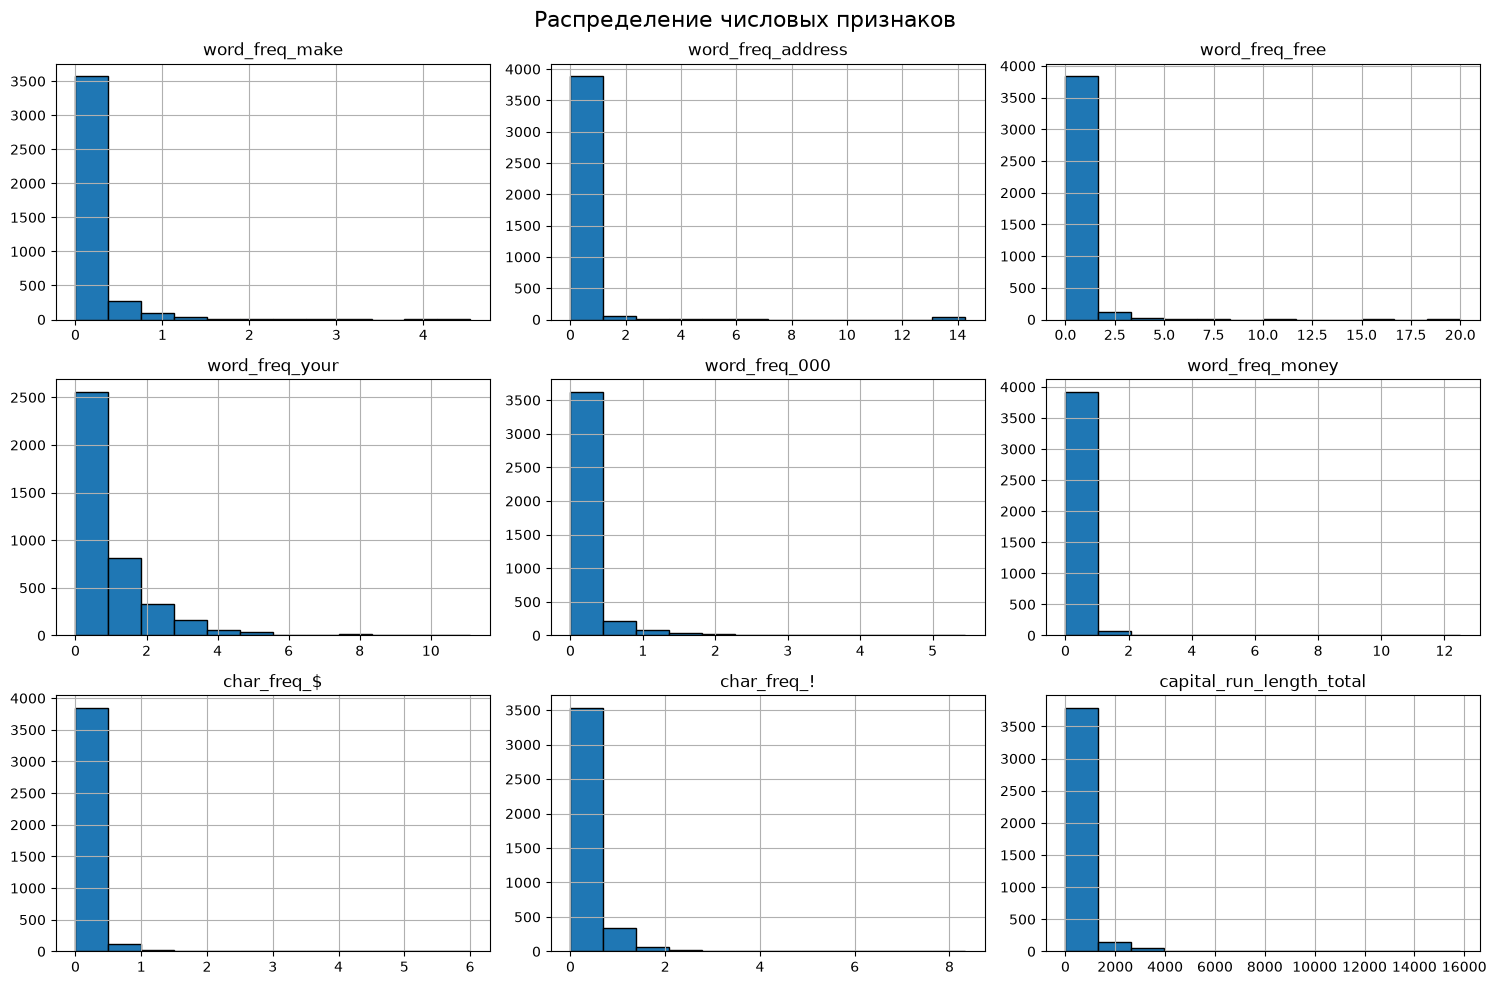

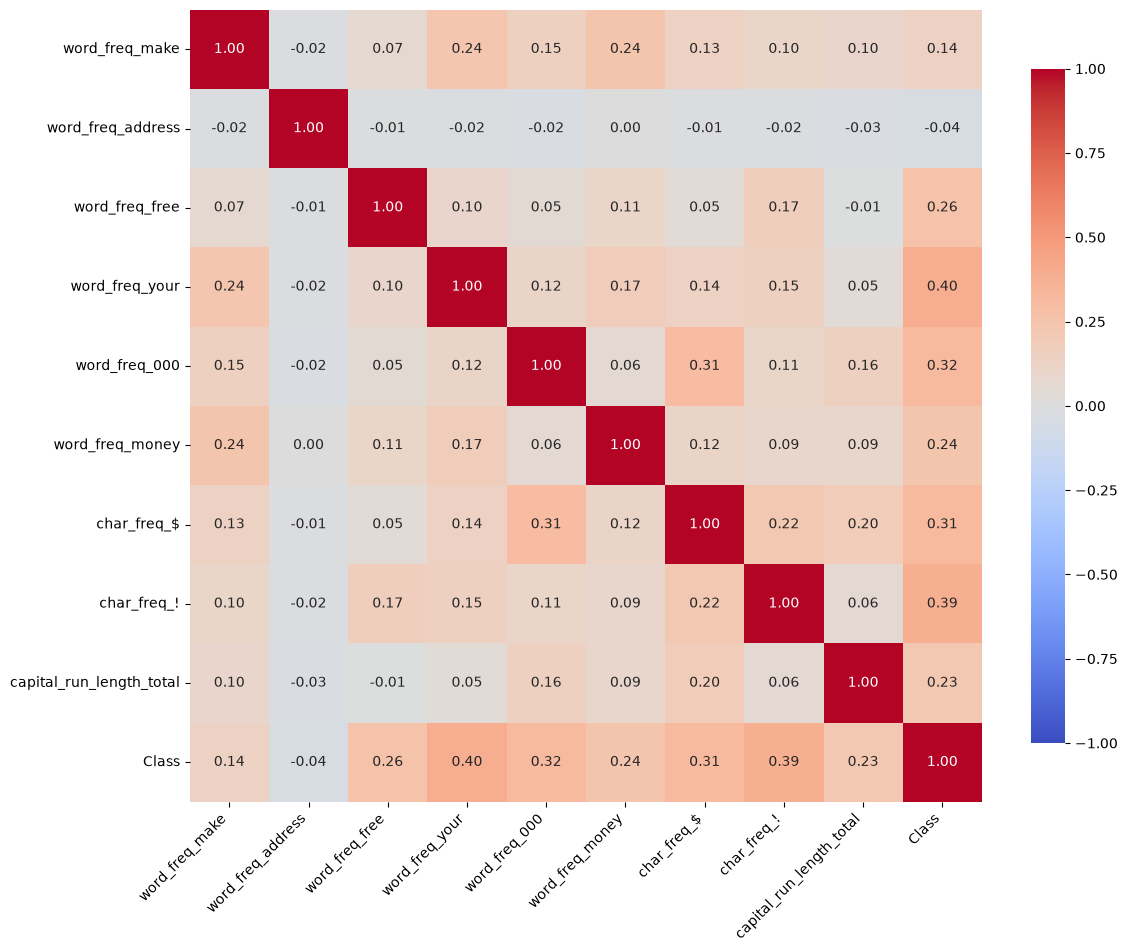

In [174]:


numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
valid_cols = [c for c in numeric_cols if df[c].std() > 1e-6]

print(f"Оставлено {len(valid_cols)} из {len(numeric_cols)} столбцов\n")

features_only = [c for c in valid_cols if c != TARGET] \
                if 'TARGET' in globals() else valid_cols


data = {'Параметр': [], 'Асимметрия': [], 'Эксцесс': []}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for col in features_only:
        vals = df[col].dropna()
        data['Параметр'].append(col)
        data['Асимметрия'].append(skew(vals))
        data['Эксцесс'].append(kurtosis(vals))

summary_df = pd.DataFrame(data)
print(summary_df.round(4))


print("\nПроверка нормальности (тест Д’Агостино-Пирсона):")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for col in features_only:
        vals = df[col].dropna()
        if len(vals) < 8:
            print(f"{col}: пропущено (мало данных)\n")
            continue
        stat, p = normaltest(vals)
        verdict = ("близко к нормальному"
                   if p > 0.05 else "отличается от нормального")
        print(f"{col}: статистика={stat:.4f}, "
              f"p-значение={p:.4f} → {verdict}\n")


count_of_bins = int(1 + 3.322 * math.log10(df.shape[0]))
print(f"Число бинов по формуле Стерджеса: {count_of_bins}\n")

df[features_only].hist(
    bins=count_of_bins,
    figsize=(15, 10),
    edgecolor="black"
)
plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

corr_matrix = df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1, vmax=1,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Дескриптивный и корреляционный анализ

**Дескриптивный анализ** показал, что признаки имеют разный масштаб (`capital_run_length_total` достигает тысяч, `word_freq_*` — единиц) и не соответствуют нормальному распределению. Это определяет необходимость стандартизации для части моделей:

- **GaussianNB** — оценивает μ и σ по каждому признаку; разный масштаб перекашивает вклад признаков в апостериорные вероятности. Стандартизация улучшает численную устойчивость модели.
- **LinearDiscriminantAnalysis (LDA)** — предполагает нормальность признаков внутри классов и равенство ковариационных матриц. При разном масштабе матрица ковариации плохо обусловлена, что приводит к неустойчивым коэффициентам. Стандартизация устраняет эту проблему.
- **Support Vector Machines (SVM)** — расстояние между точками и ширина margin зависят от масштаба; без стандартизации признаки с большим разбросом доминируют, и модель работает неоптимально.
- **k-Nearest Neighbors (KNN)** — использует евклидово расстояние; без стандартизации признаки с большим разбросом подавляют вклад остальных в расстояние между объектами.

**Корреляционный анализ** показал, что признаки слабо коррелируют друг с другом - мультиколлинеарность отсутствует, поэтому дополнительных преобразований не требуется.

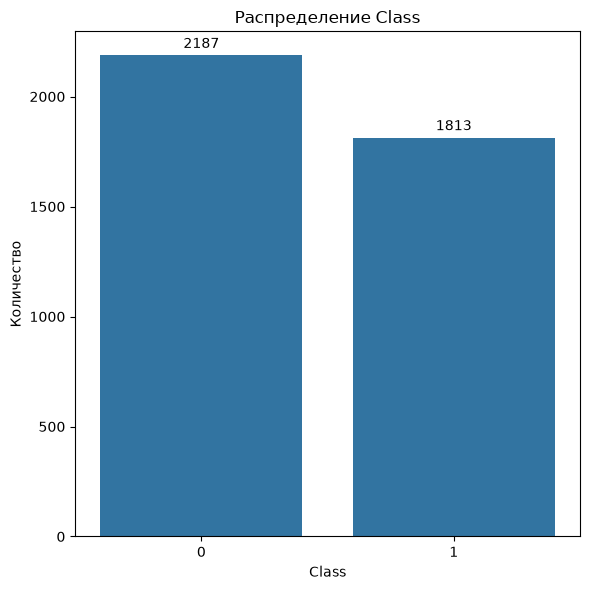

ДИАГНОСТИКА ДАТАСЕТА

[ЦЕЛЕВАЯ ПЕРЕМЕННАЯ]
  Объектов:           4000
  Классов:            2
  Мин. класс:         1813 (45.32%)
  Макс. класс:        2187 (54.67%)
  Imbalance ratio:    1.21
  CV частот:          0.132

[ПРИЗНАКИ]
  Форма:              (4000, 9)
  Разреженность:      61.57%
  Плотность:          38.43%


In [175]:

X = df.drop(columns=[TARGET]).select_dtypes(include='number')
y = df[TARGET]

plt.figure(figsize=(6, 6))
ax = sns.countplot(x=TARGET, data=df)
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.title(f"Распределение {TARGET}")
plt.xlabel(TARGET)
plt.ylabel("Количество")
plt.tight_layout()
plt.show()


def diagnose_dataset(X, y):
    print("ДИАГНОСТИКА ДАТАСЕТА")
    counts = y.value_counts().sort_index()
    n_total = len(y)
    min_c, max_c = counts.min(), counts.max()

    print("\n[ЦЕЛЕВАЯ ПЕРЕМЕННАЯ]")
    print(f"  Объектов:           {n_total}")
    print(f"  Классов:            {y.nunique()}")
    print(f"  Мин. класс:         {min_c} ({min_c/n_total:.2%})")
    print(f"  Макс. класс:        {max_c} ({max_c/n_total:.2%})")
    print(f"  Imbalance ratio:    {max_c/min_c:.2f}")
    print(f"  CV частот:          {counts.std()/counts.mean():.3f}")

    sparsity = (X == 0).sum().sum() / X.size

    print("\n[ПРИЗНАКИ]")
    print(f"  Форма:              {X.shape}")
    print(f"  Разреженность:      {sparsity:.2%}")
    print(f"  Плотность:          {1-sparsity:.2%}")


diagnose_dataset(X, y)

**Интерпретация результатов:**

Выборка является умеренно сбалансированной:
- **1 (спам):** 2187 записей (54.67%) — мажоритарный класс;
- **2 (не спам):** 1813 запись (~45.32%) — миноритарный класс;

Различия между количеством данных в обоих классах незначительны.


### Категоризованные диаграммы рассеивания: Топ-2 признака и PCA
Визуализируем разделимость классов в двумерном пространстве:
1. По двум признакам с самой большой корреляцией с целевой переменной.
2. В пространстве двух главных компонент (PCA), сжимающих все признаки.


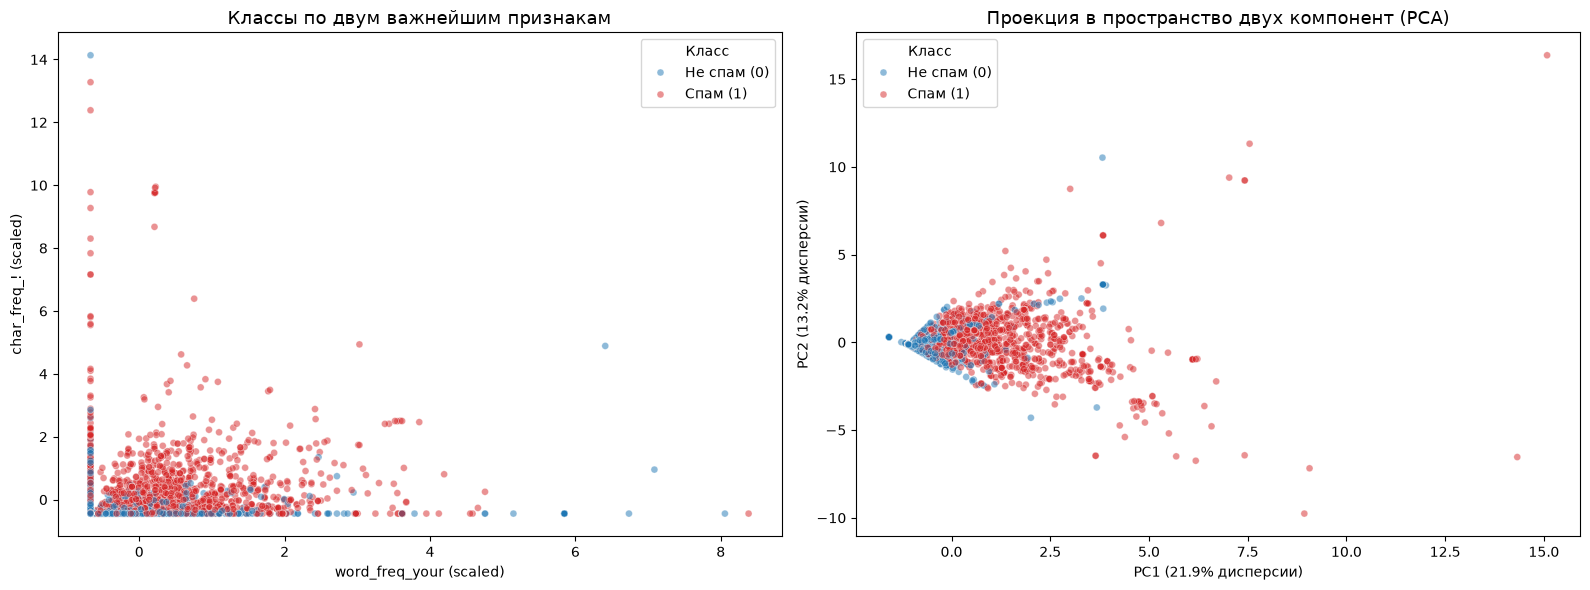

In [176]:
X = df.drop(TARGET, axis=1)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
feature_names = X_train.columns.tolist()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_names,
    index=X_train.index
)
X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=feature_names,
    index=X_test.index
)

X_train_df = X_train_scaled_df.copy()

X_train_df['Target'] = y_train.astype(int).values


palette = {0: 'tab:blue', 1: 'tab:red'}
labels = {0: 'Не спам (0)', 1: 'Спам (1)'}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#  Топ-2 признака
fx, fy = 'word_freq_your', 'char_freq_!'

sns.scatterplot(
    data=X_train_df,
    x=fx,
    y=fy,
    hue='Target',
    palette=palette,
    hue_order=[0, 1],
    alpha=0.5,
    s=25,
    ax=axes[0]
)
axes[0].set_title('Классы по двум важнейшим признакам', fontsize=13)
axes[0].set_xlabel(f'{fx} (scaled)')
axes[0].set_ylabel(f'{fy} (scaled)')
# Получаем текущие handle-ы и задаем правильные метки
handles, _ = axes[0].get_legend_handles_labels()
axes[0].legend(handles=handles, title='Класс', labels=[labels[0], labels[1]])

# График 2: PCA проекция
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=X_train.index)
pca_df['Target'] = y_train.astype(int).values

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Target',
    palette=palette,
    hue_order=[0, 1],
    alpha=0.5,
    s=25,
    ax=axes[1]
)
axes[1].set_title('Проекция в пространство двух компонент (PCA)', fontsize=13)
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)')
handles_pca, _ = axes[1].get_legend_handles_labels()
axes[1].legend(handles=handles_pca, title='Класс', labels=[labels[0], labels[1]])

plt.tight_layout()
plt.show()

**Интерпретация результатов:**
- **Диаграмма по двум главным признакам:** 

В области малых значений признаков наблюдается значительное перекрытие точек двух классов.

Чёткая линейная граница между классами не прослеживается

- **PCA-проекция:** 

Первая главная компонента объясняет около 21,9% дисперсии данных, а вторая - около 13,2%. В сумме они объясняют приблизительно 35,1% общей дисперсии.

Точки двух классов существенно перекрываются и образуют области со схожим распределением. Информация рассредоточена по многим измерениям, и решение задачи требует нелинейных моделей.

### Построение классификационных моделей и оценка классификации с помощью метрик

Классификационные модели были построены с помощью 5 методов: 

- Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

- Деревья решений (Decision Tree);

- Линейный дискриминантный анализ (Linear Discriminant Analysis);

- Метод опорных векторов (Support Vector Machines);

- Метод ближайших соседей (k-Nearest Neighbors);

Модели оценивались с помощью следующих метрик:

- Accuracy (точность),

- Precision (доля правильно классифицированных положительных примеров),

- Recall (чувствительность, доля верно найденных положительных примеров),

- F1-Score (среднее гармоническое precision и recall),

- Площадь под кривой ROC (AUC-ROC).

Были построены ROC- и PR-кривые, матрица ошибок.


In [177]:


def print_result(model, y_pred, y_test, method, X_test,
                 display_labels=("Класс 0", "Класс 1"),
                 feature_indexes=[0, 1]):

    n_total = len(y_test)
    n_correct = (y_test == y_pred).sum()
    n_wrong = n_total - n_correct

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

    print()
    print(f"РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ {method}")
    print()
    print(f"Всего объектов в тесте : {n_total}")
    print(f"Правильно предсказано  : {n_correct} ({n_correct/n_total:.1%})")
    print(f"Ошибок                 : {n_wrong} ({n_wrong/n_total:.1%})")
    print(f"Accuracy               : {acc:.4f}")
    print(f"Precision (macro)      : {prec:.4f}")
    print(f"Recall    (macro)      : {rec:.4f}")
    print(f"F1-score  (macro)      : {f1:.4f}")

    # Вероятности для AUC
    y_proba = None
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X_test)
        if proba.ndim == 2 and proba.shape[1] > 1:
            y_proba = proba[:, 1]
        else:
            y_proba = proba.ravel()
    elif hasattr(model, "decision_function"):
        y_proba = model.decision_function(X_test)

    auc_value = None
    try:
        auc_value = roc_auc_score(y_test, y_proba)
        print(f"AUC-ROC                : {auc_value:.4f}")
    except ValueError as e:
        print(f"AUC-ROC                : — ({e})")
    print()

    # Матрица ошибок
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(6, 6))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Матрица ошибок — {method}")
    plt.tight_layout()
    plt.show()

    # ROC-кривая
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc_val = auc(fpr, tpr)

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, lw=2,
             label=f'{method} (AUC = {roc_auc_val:.4f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный классификатор')
    plt.title(f'ROC-кривая — {method}')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # PR-кривая
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    baseline = y_test.mean()

    plt.figure(figsize=(7, 6))
    plt.plot(recall_curve, precision_curve, lw=2,
             label=f'{method} (AP = {ap:.4f})')
    plt.axhline(baseline, color='k', ls='--', lw=1,
                label=f'Случайный классификатор (доля класса = {baseline:.3f})')
    plt.title(f'PR-кривая — {method}')
    plt.xlabel('Recall (полнота)')
    plt.ylabel('Precision (точность)')
    plt.legend(loc='lower left')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    y_train_encoded = le.transform(y_train)
    X_feature_columns = X.iloc[:, feature_indexes].values
    X_train_feature_columns = X_train.iloc[:, feature_indexes].values
    model.fit(X_train_feature_columns, y_train_encoded)
    plot_decision_regions(X=X_feature_columns, y=y_encoded, clf=model)
    plt.title(method)
    plt.show()

    print("\n")

# Наивный Байесовский

- **Гауссовский наивный байесовский классификатор (GaussianNB)** — вариант для работы с непрерывными признаками, которые имеют нормальное (гауссовское) распределение.

- **Мультиномиальный наивный байесовский классификатор (MultinomialNB)** — вариант для работы с дискретными признаками, которые имеют мультиномиальное распределение.

- **Комплементарный наивный байесовский классификатор (ComplementNB)** — улучшенный вариант MultinomialNB, подходящий для несбалансированных наборов данных.

- **Бернуллиевский наивный байесовский классификатор (BernoulliNB)** — ещё один вариант для работы с дискретными признаками, но которые имеют бернуллиевское распределение

Лучший результат показал **BernoulliNB** - Accuracy = 0.8187

Худший результат показал **ComplementNB** - Accuracy = 0.7650


РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ GaussianNB

Всего объектов в тесте : 800
Правильно предсказано  : 637 (79.6%)
Ошибок                 : 163 (20.4%)
Accuracy               : 0.7963
Precision (macro)      : 0.8181
Recall    (macro)      : 0.7929
F1-score  (macro)      : 0.7913
AUC-ROC                : 0.8896



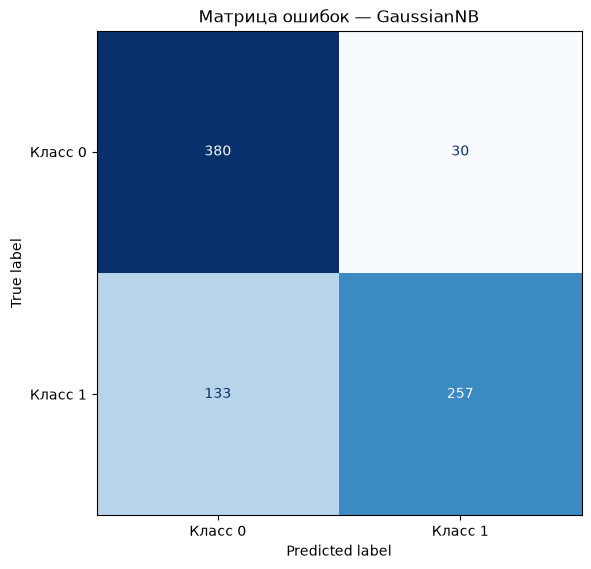

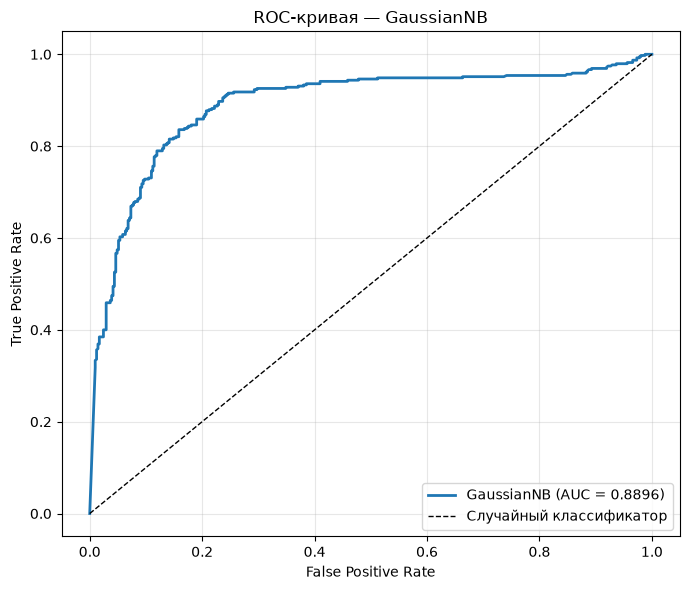

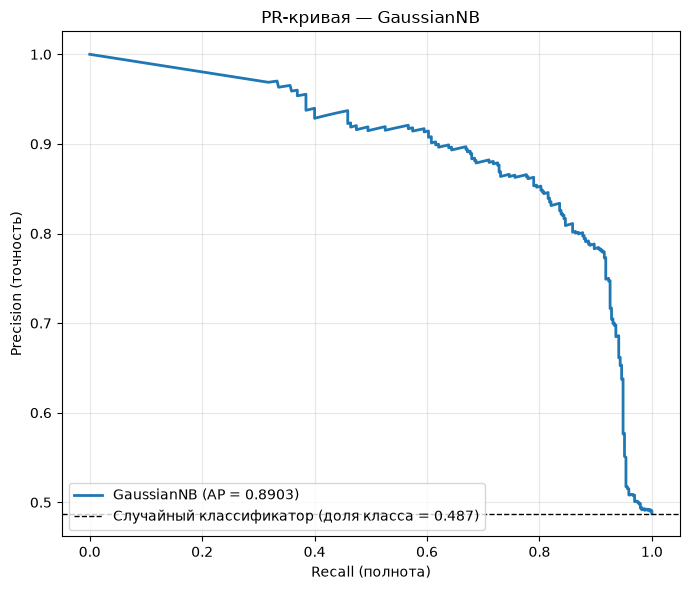

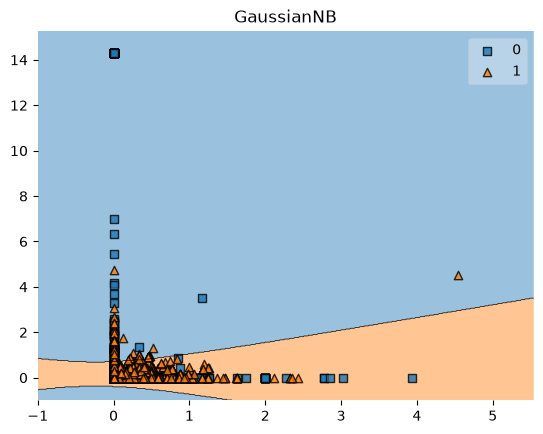




РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ MultinomialNB

Всего объектов в тесте : 800
Правильно предсказано  : 635 (79.4%)
Ошибок                 : 165 (20.6%)
Accuracy               : 0.7937
Precision (macro)      : 0.7941
Recall    (macro)      : 0.7932
F1-score  (macro)      : 0.7934
AUC-ROC                : 0.8010



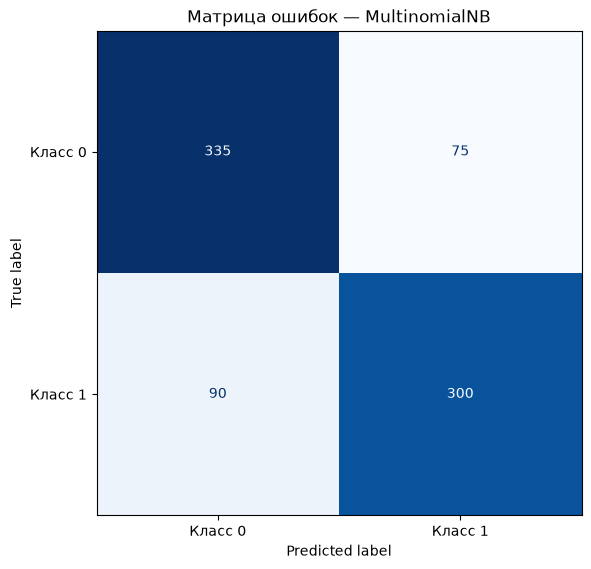

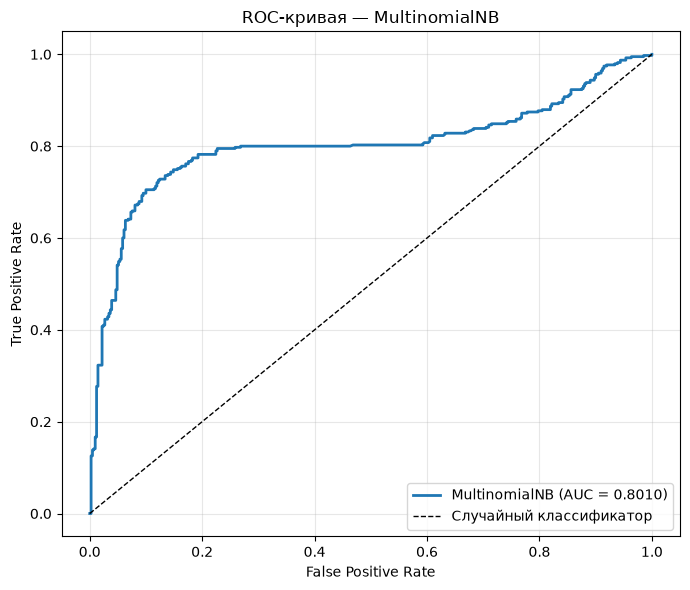

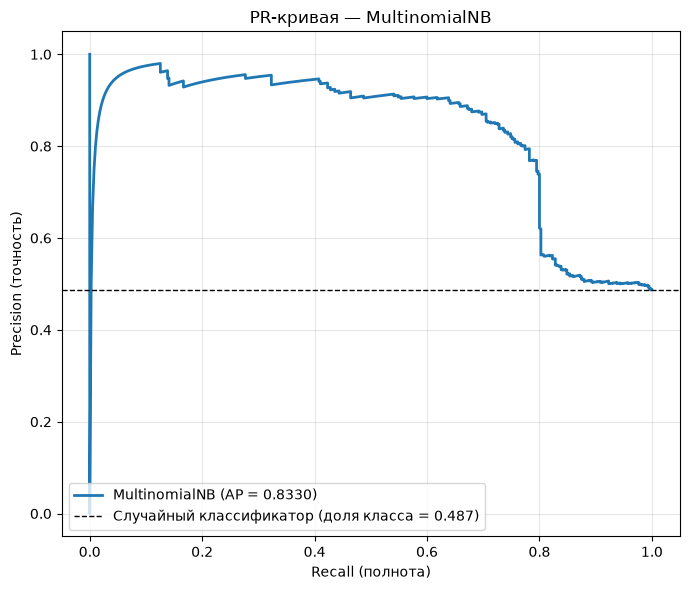

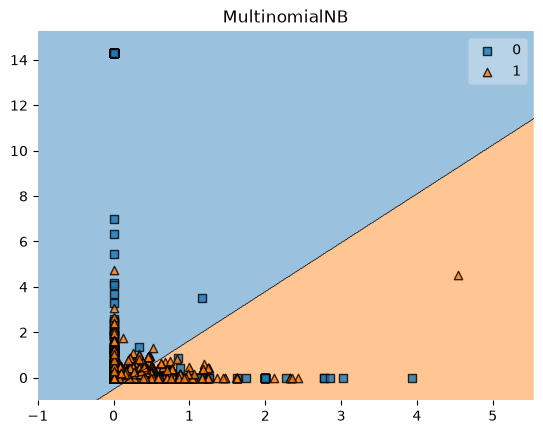




РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ ComplementNB

Всего объектов в тесте : 800
Правильно предсказано  : 612 (76.5%)
Ошибок                 : 188 (23.5%)
Accuracy               : 0.7650
Precision (macro)      : 0.7665
Recall    (macro)      : 0.7659
F1-score  (macro)      : 0.7649
AUC-ROC                : 0.8010



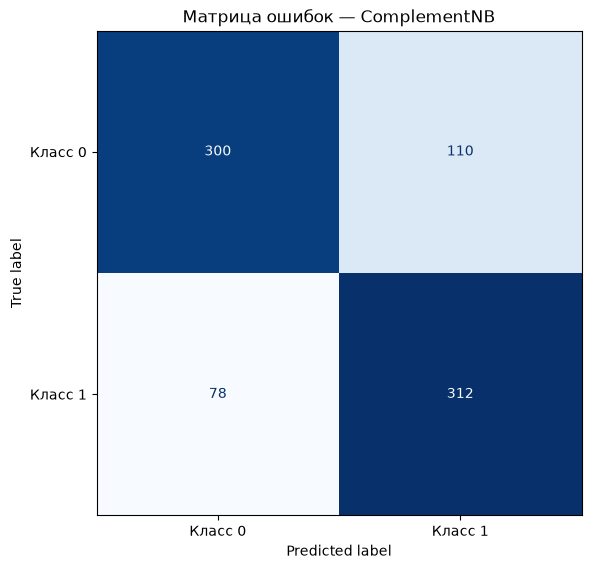

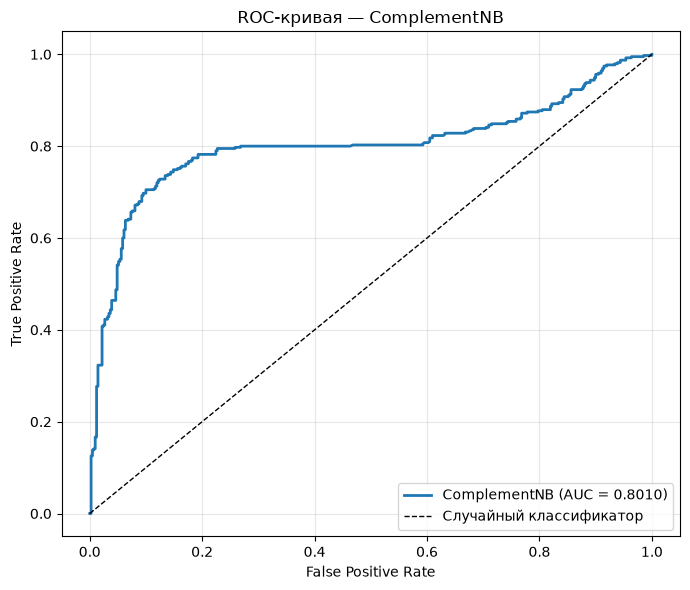

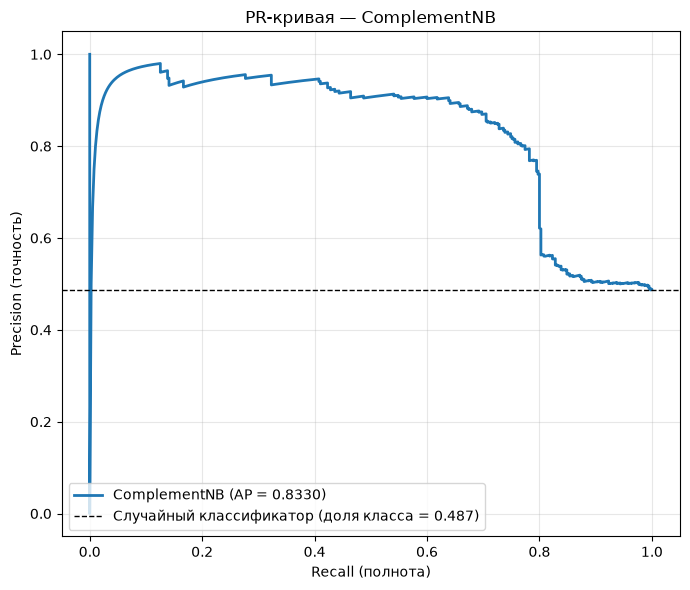

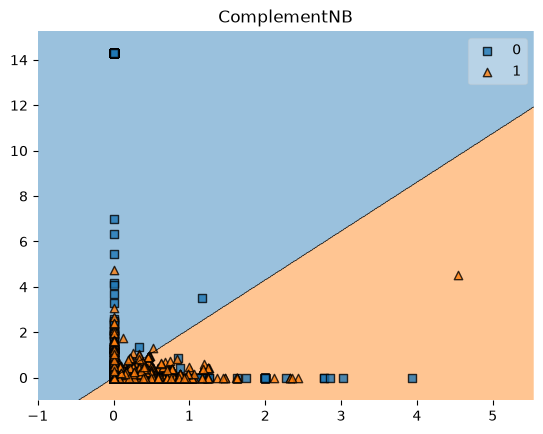




РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ BernoulliNB

Всего объектов в тесте : 800
Правильно предсказано  : 655 (81.9%)
Ошибок                 : 145 (18.1%)
Accuracy               : 0.8187
Precision (macro)      : 0.8231
Recall    (macro)      : 0.8172
F1-score  (macro)      : 0.8175
AUC-ROC                : 0.9041



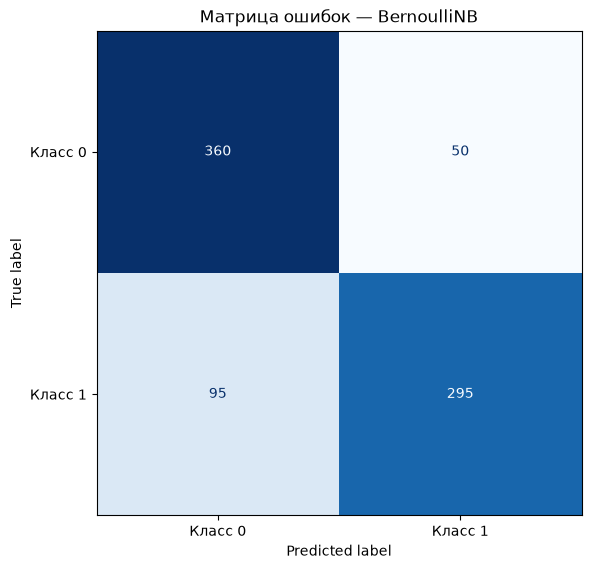

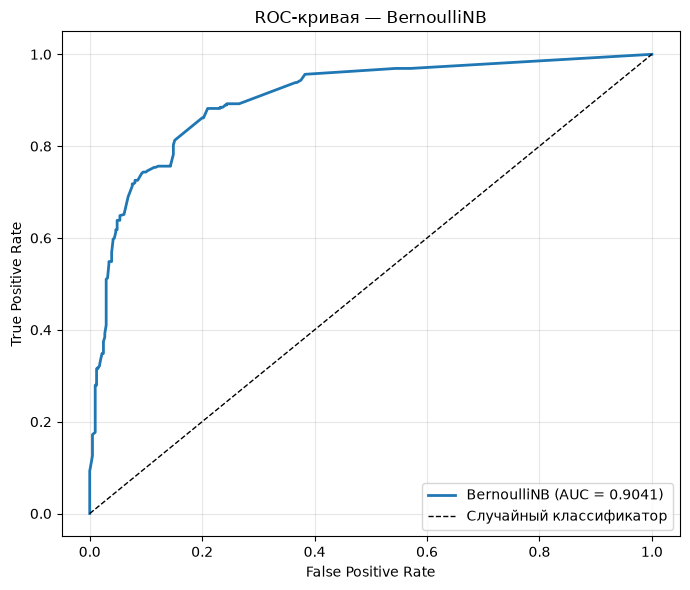

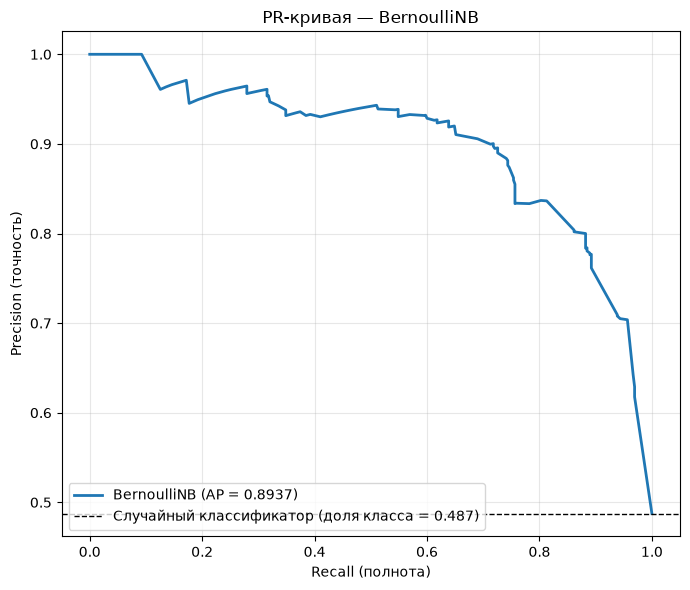

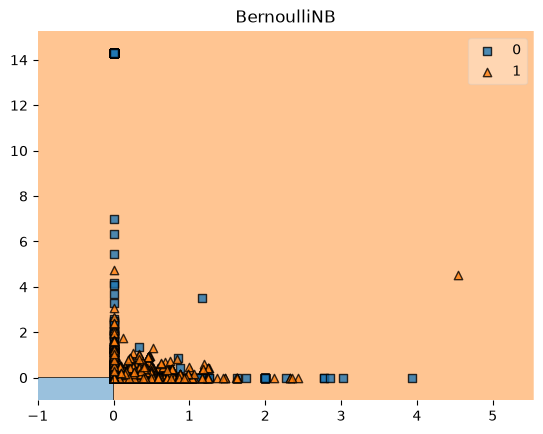

In [178]:


gnb = GaussianNB()
y_pred = gnb.fit(X_train_scaled, y_train).predict(X_test_scaled)
print_result(gnb, y_pred, y_test, "GaussianNB", X_test_scaled)

mnb = MultinomialNB()
y_pred = mnb.fit(X_train, y_train).predict(X_test)
print_result(mnb, y_pred, y_test, "MultinomialNB", X_test)

cnb = ComplementNB()
y_pred = cnb.fit(X_train, y_train).predict(X_test)
print_result(cnb, y_pred, y_test, "ComplementNB", X_test)

bnb = BernoulliNB()
y_pred = bnb.fit(X_train, y_train).predict(X_test)
print_result(bnb, y_pred, y_test, "BernoulliNB", X_test)

# Дерево решений

Дерево решений - метод классификации, который строит модель в виде иерархии правил «если–то», последовательно разбивающих данные по признакам, чтобы предсказать метку класса. Алгоритм пошагово делит данные на подмножества по значениям признаков, чтобы получить группы, где объекты принадлежат одному классу.

Фактическая глубина дерева: 3
Количество листьев: 8

Важность признаков:
                 Признак  Важность
             char_freq_!  0.646447
             char_freq_$  0.212609
          word_freq_free  0.119843
          word_freq_your  0.021101
          word_freq_make  0.000000
           word_freq_000  0.000000
       word_freq_address  0.000000
         word_freq_money  0.000000
capital_run_length_total  0.000000

РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ Дерево решений (Decision Tree)

Всего объектов в тесте : 800
Правильно предсказано  : 667 (83.4%)
Ошибок                 : 133 (16.6%)
Accuracy               : 0.8337
Precision (macro)      : 0.8454
Recall    (macro)      : 0.8314
F1-score  (macro)      : 0.8316
AUC-ROC                : 0.9192



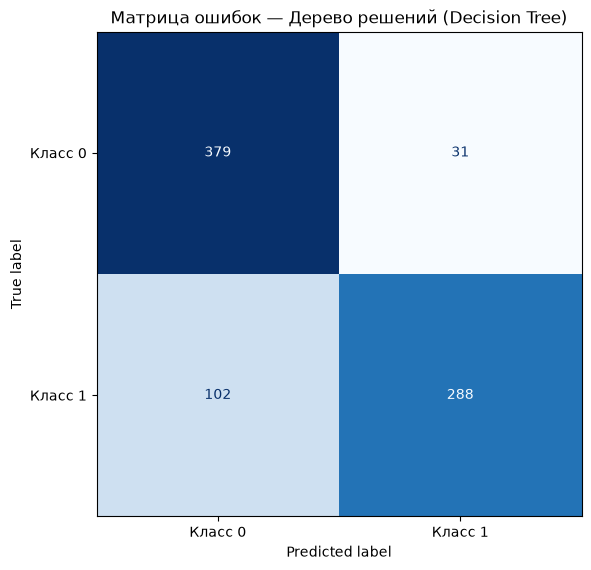

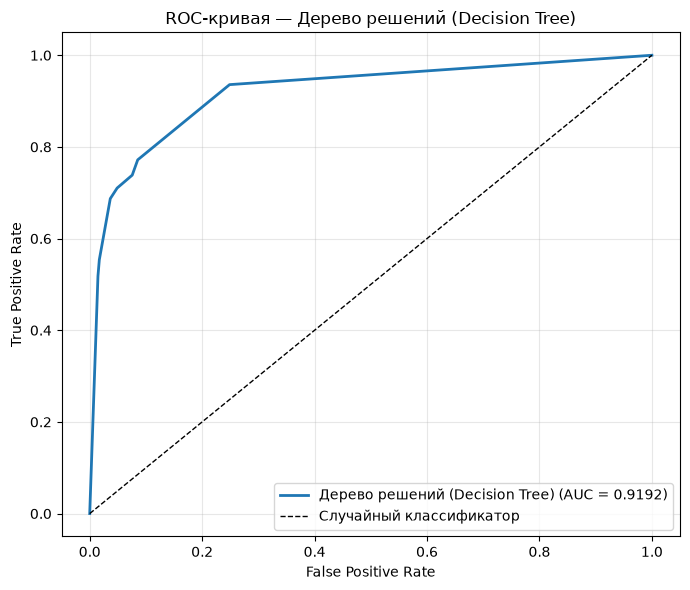

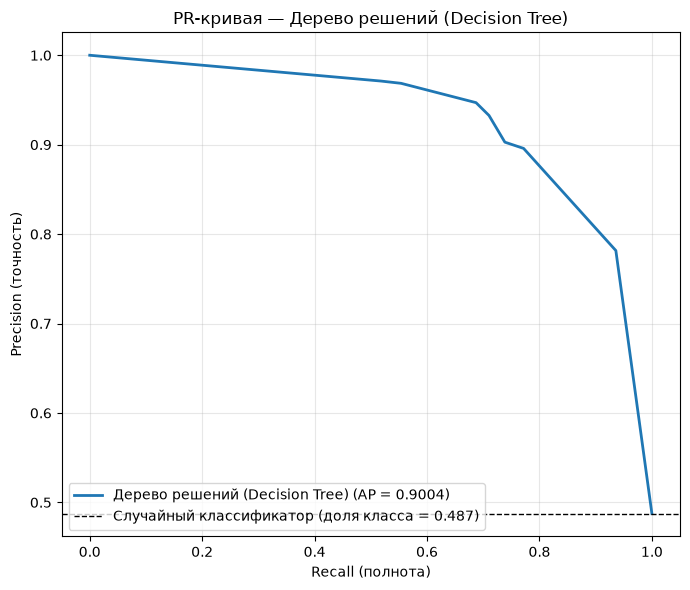

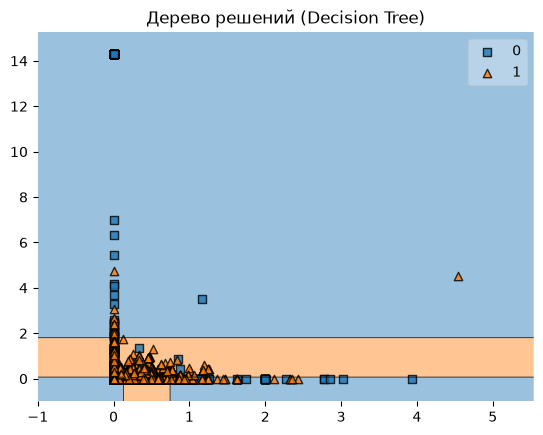

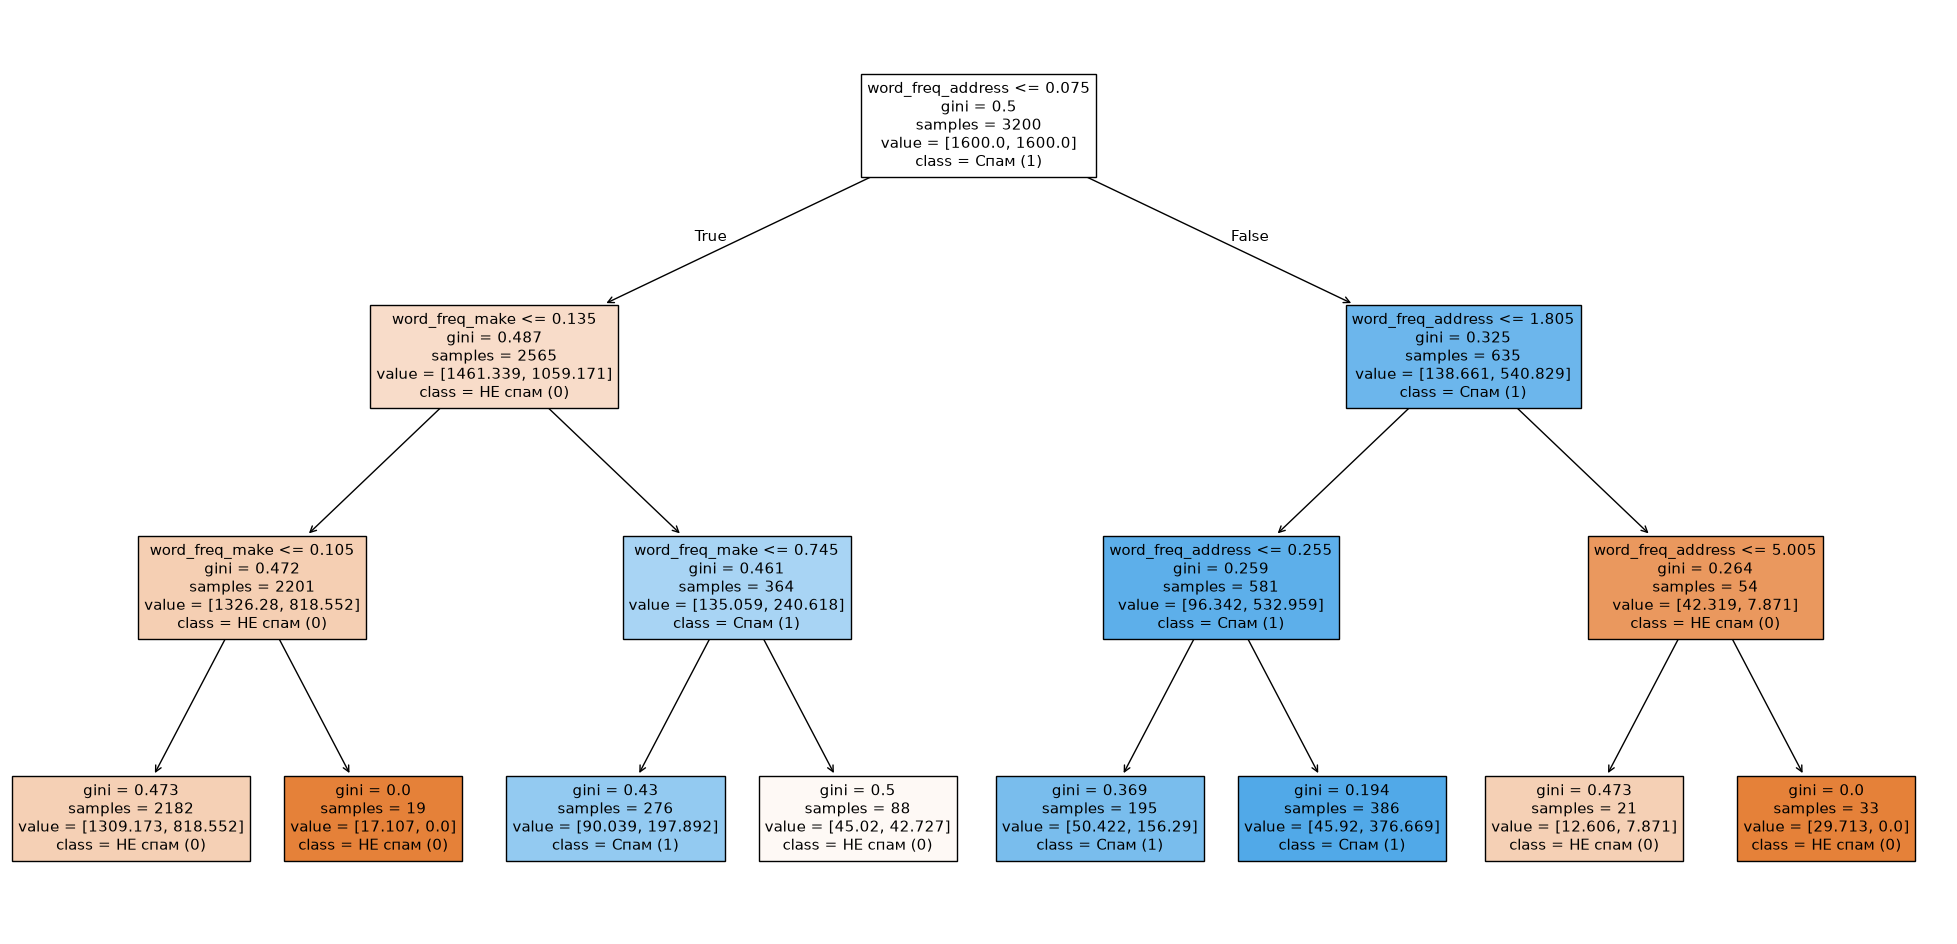

In [179]:
dt = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=0
)
y_pred = dt.fit(X_train, y_train).predict(X_test)
depth = dt.get_depth()           
n_leaves = dt.get_n_leaves()    

print(f"Фактическая глубина дерева: {depth}")
print(f"Количество листьев: {n_leaves}")

importances = dt.feature_importances_
features = X_train.columns

importance_df = pd.DataFrame({
    'Признак': features,
    'Важность': importances
}).sort_values(by='Важность', ascending=False)

print("\nВажность признаков:")
print(importance_df.to_string(index=False))

print_result(dt, y_pred, y_test, "Дерево решений (Decision Tree)", X_test)
plt.figure(figsize=(25, 12))
plot_tree(dt, filled=True, feature_names=X.columns, class_names=["НЕ спам (0)", "Спам (1)"])
plt.show()

# Линейный дискриминантный анализ
LDA (Linear Discriminant Analysis, линейный дискриминантный анализ) — это метод классификации и снижения размерности, который ищет линейные комбинации признаков, максимально разделяющие классы.
LDA строит такие проекции данных, при которых:
- разброс между классами (межклассовая дисперсия) - максимален,
- разброс внутри классов - минимален.


РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ Линейный дискриминантный анализ

Всего объектов в тесте : 800
Правильно предсказано  : 649 (81.1%)
Ошибок                 : 151 (18.9%)
Accuracy               : 0.8113
Precision (macro)      : 0.8239
Recall    (macro)      : 0.8087
F1-score  (macro)      : 0.8084
AUC-ROC                : 0.9068



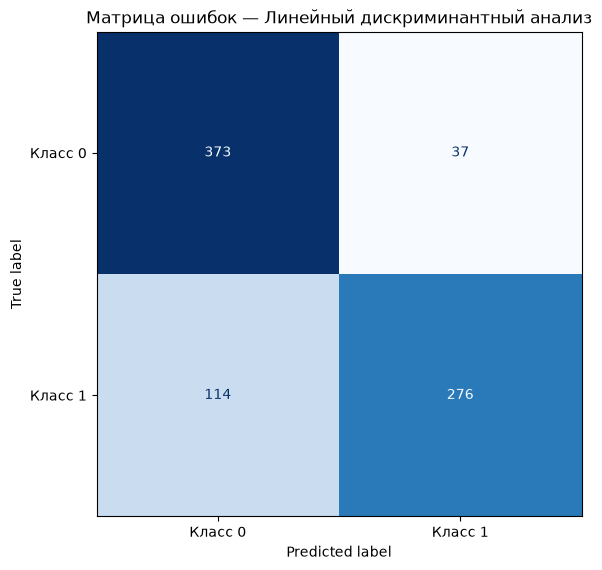

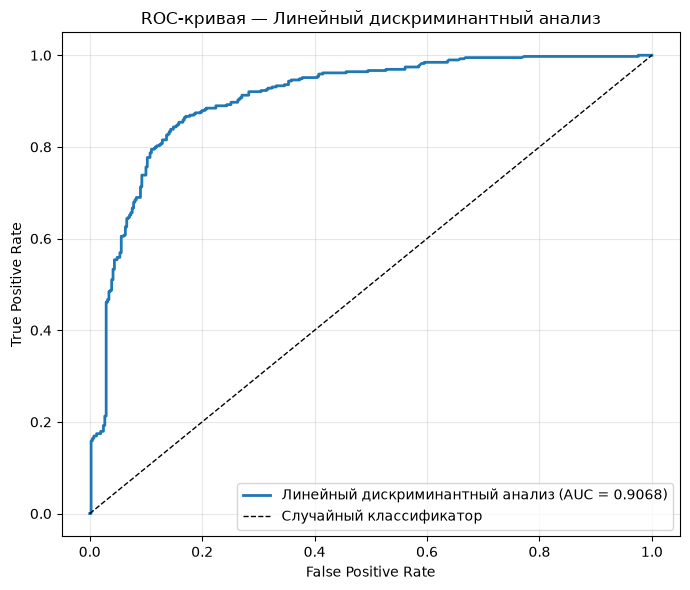

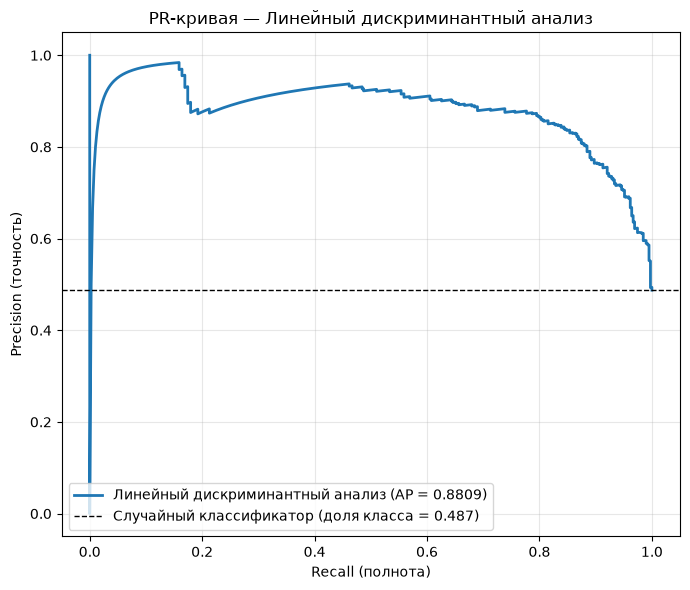

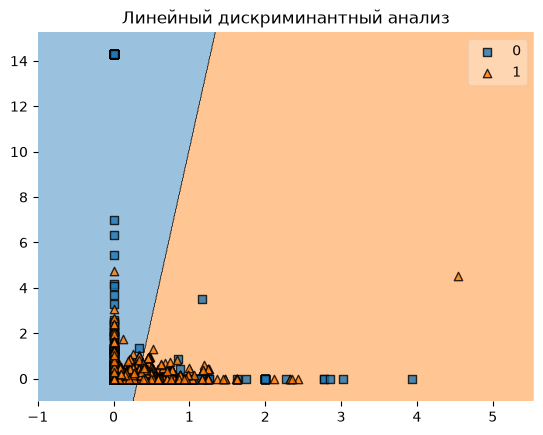

In [180]:
lda = LinearDiscriminantAnalysis()
y_pred = lda.fit(X_train_scaled, y_train).predict(X_test_scaled)
print_result(lda, y_pred, y_test, "Линейный дискриминантный анализ", X_test_scaled)


# SVM
SVM (Support Vector Machine, метод опорных векторов) — это алгоритм классификации, который ищет оптимальную разделяющую гиперплоскость между классами.

Принцип работы
1. Для линейно разделимых данных строится гиперплоскость: w^T * x + b = 0
2. Оптимизируется расстояние между гиперплоскостью и ближайшими точками (векторами) классов.
3. Для нелинейных данных используется ядровой трюк (kernel trick) — преобразование данных в более высокое пространство признаков, где разделение становится линейным.


РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ SVC (RBF, scaled)

Всего объектов в тесте : 800
Правильно предсказано  : 715 (89.4%)
Ошибок                 : 85 (10.6%)
Accuracy               : 0.8938
Precision (macro)      : 0.8966
Recall    (macro)      : 0.8927
F1-score  (macro)      : 0.8933
AUC-ROC                : 0.9355



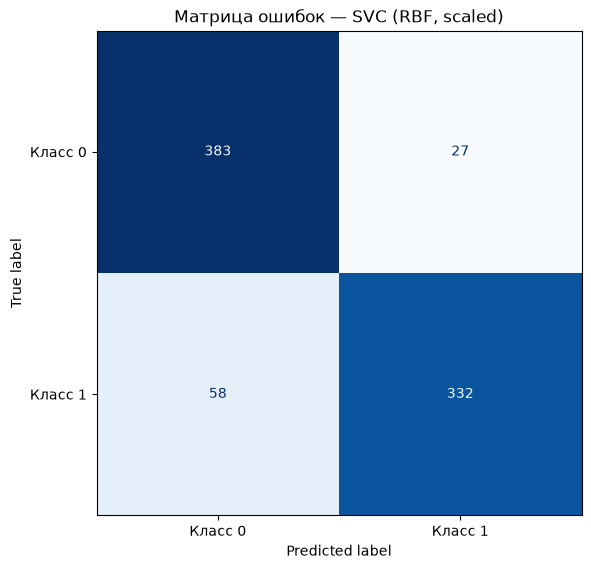

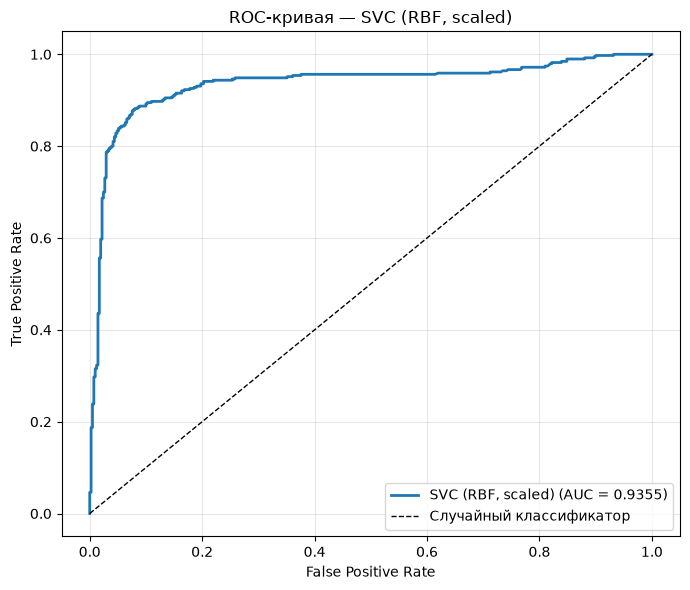

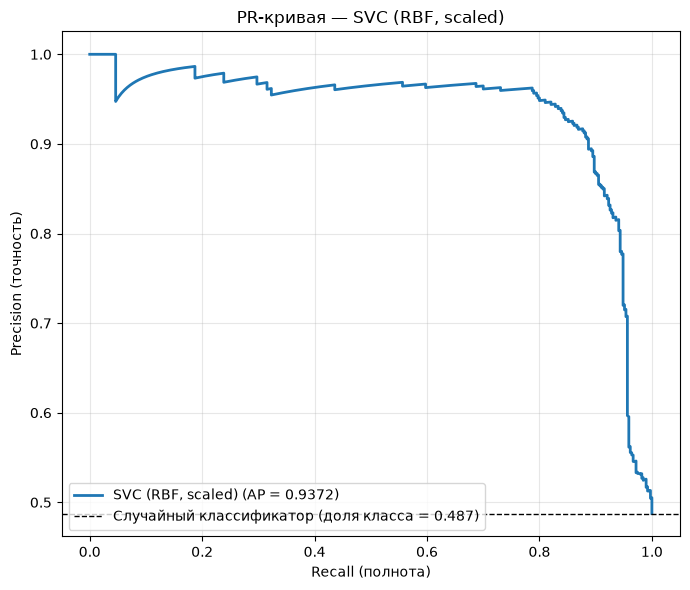

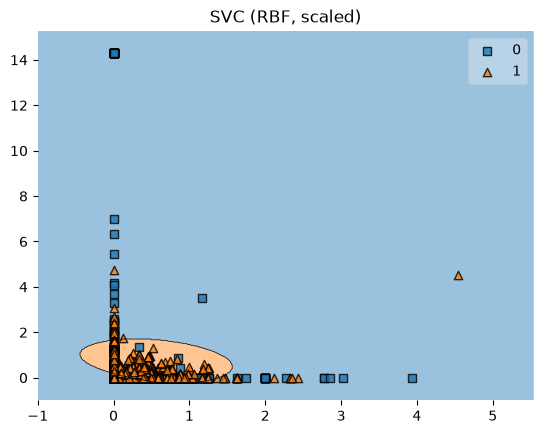

In [181]:
svm_clf = SVC(kernel='rbf', random_state=0)
y_pred = svm_clf.fit(X_train_scaled, y_train).predict(X_test_scaled)
print_result(svm_clf, y_pred, y_test, "SVC (RBF, scaled)", X_test_scaled)

# Метод ближайших соседей

KNN (k-Nearest Neighbors, метод k ближайших соседей) — это простой неметрический метод классификации, основанный на сходстве объектов.

Чтобы классифицировать новый объект, алгоритм:

1. Находит k ближайших обучающих объектов (по метрике расстояния).
2. Смотрит, какие классы преобладают среди этих соседей.
3. Присваивает объекту тот класс, который встречается чаще всего.


РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ Метод ближайших соседей (k-NN, k=5)

Всего объектов в тесте : 800
Правильно предсказано  : 715 (89.4%)
Ошибок                 : 85 (10.6%)
Accuracy               : 0.8938
Precision (macro)      : 0.8952
Recall    (macro)      : 0.8930
F1-score  (macro)      : 0.8935
AUC-ROC                : 0.9452



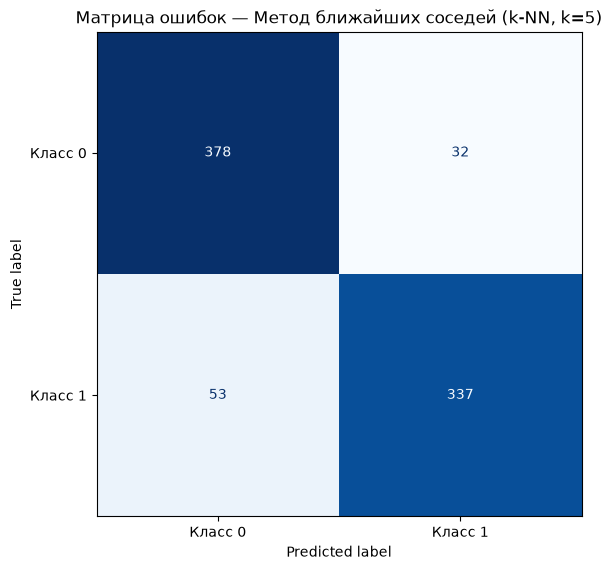

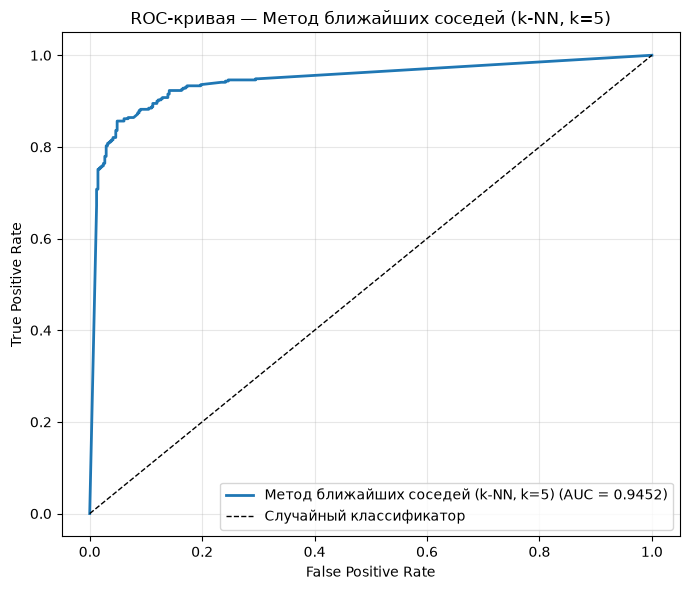

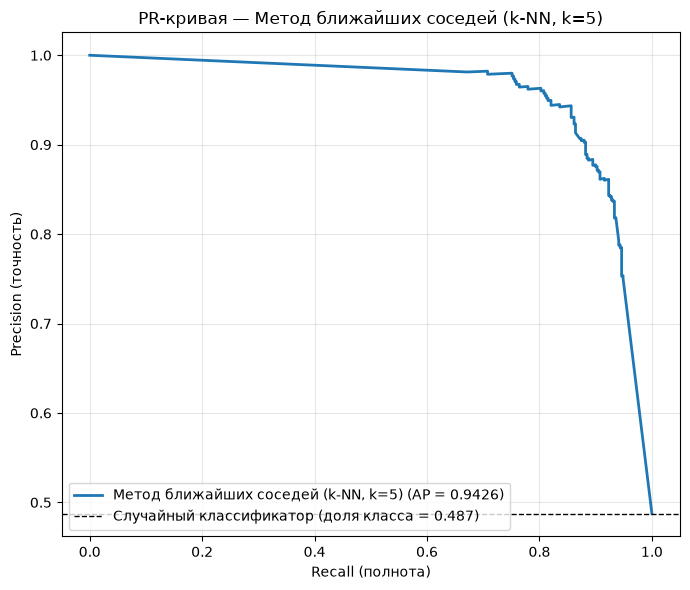

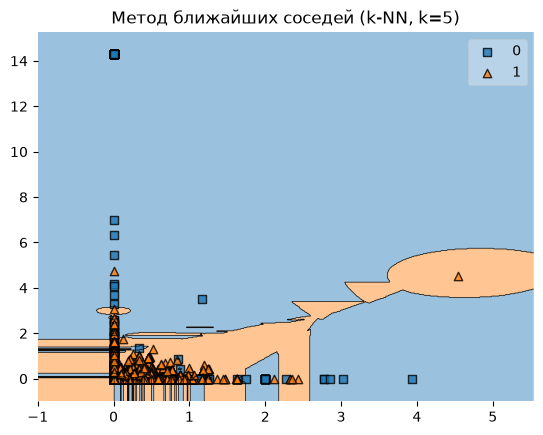

In [182]:
knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski",
    p=2
)
y_pred = knn.fit(X_train_scaled, y_train).predict(X_test_scaled)
print_result(knn, y_pred, y_test, "Метод ближайших соседей (k-NN, k=5)", X_test_scaled)

In [183]:


def evaluate_model(model, X_tr, X_te, name, scale_note="—"):
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba = model.decision_function(X_te)
    else:
        y_proba = None

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    try:
        auc = roc_auc_score(y_test, y_proba) if y_proba is not None else None
    except ValueError:
        auc = None

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    return {
        "Модель":        name,
        "Масштабирование": scale_note,
        "Accuracy":      round(acc, 4),
        "Precision":     round(prec, 4),
        "Recall":        round(rec, 4),
        "F1-score":      round(f1, 4),
        "AUC-ROC":       round(auc, 4) if auc is not None else "—",
        "Ошибок (из 200)": int((y_test != y_pred).sum()),
        "FP":            int(fp),
        "FN":            int(fn),
    }


results = []

results.append(evaluate_model(
    GaussianNB(), X_train_scaled, X_test_scaled,
    "GaussianNB"))

results.append(evaluate_model(
    MultinomialNB(), X_train, X_test,
    "MultinomialNB"))

results.append(evaluate_model(
    ComplementNB(), X_train, X_test,
    "ComplementNB"))

results.append(evaluate_model(
    BernoulliNB(), X_train, X_test,
    "BernoulliNB"))

results.append(evaluate_model(
    DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=0),
    X_train, X_test,
    "DecisionTree"))

results.append(evaluate_model(
    LinearDiscriminantAnalysis(), X_train, X_test,
    "LinearDiscriminant"))

results.append(evaluate_model(
    KNeighborsClassifier(n_neighbors=5, weights="distance", p=2),
    X_train_scaled, X_test_scaled,
    "KNeighborsClassifier"))

results.append(evaluate_model(
    SVC(kernel="rbf", random_state=0), X_train_scaled, X_test_scaled, "SVC"))

df_results = pd.DataFrame(results).sort_values("AUC-ROC", ascending=False)
df_results = df_results.reset_index(drop=True)
df_short = df_results[["Модель", "Accuracy", "Precision",
                       "Recall", "F1-score", "AUC-ROC"]]

display(df_short.to_string(index=False, float_format="{:.4f}".format))

'              Модель  Accuracy  Precision  Recall  F1-score  AUC-ROC\nKNeighborsClassifier    0.8938     0.8952  0.8930    0.8935   0.9452\n                 SVC    0.8938     0.8966  0.8927    0.8933   0.9355\n        DecisionTree    0.8838     0.8843  0.8833    0.8836   0.9306\n  LinearDiscriminant    0.8113     0.8239  0.8087    0.8084   0.9068\n         BernoulliNB    0.8187     0.8231  0.8172    0.8175   0.9041\n          GaussianNB    0.7963     0.8181  0.7929    0.7913   0.8896\n        ComplementNB    0.7650     0.7665  0.7659    0.7649   0.8010\n       MultinomialNB    0.7937     0.7941  0.7932    0.7934   0.8010'

- **Наибольшую accuracy (0.8938)** показали две модели - **KNeighborsClassifier** и **SVC**

- **По AUC-ROC** лучшей моделью является **KNeighborsClassifier (0.9452)**.

### Итоговый вывод

Среди восьми рассмотренных моделей **KNeighborsClassifier** показал лучшее качество по метрике **AUC-ROC = 0.9452** и наибольшую **accuracy = 0.8938**. **SVC** показал второй результат (accuracy = 0.8938 AUC = 0.9355). Обе модели демонстрируют сбалансированные Precision, Recall и F1-score (все ≈ 0.89), что говорит об отсутствии смещения в сторону одного из классов.

**Худшую точность** показали методы наивного Байесовского классификатора - **GaussianNB, MultinomialNB и ComplementNB**. 

Их ограничения связаны с нарушением модельных предпосылок (нормальность, независимость, частотная природа признаков).

# Исследование влияния гиперпараметров на качество классификации

### Наивный Байесовский

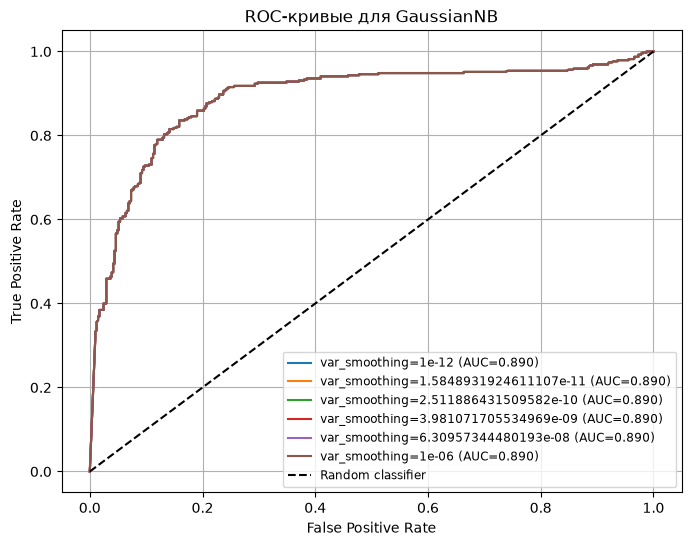

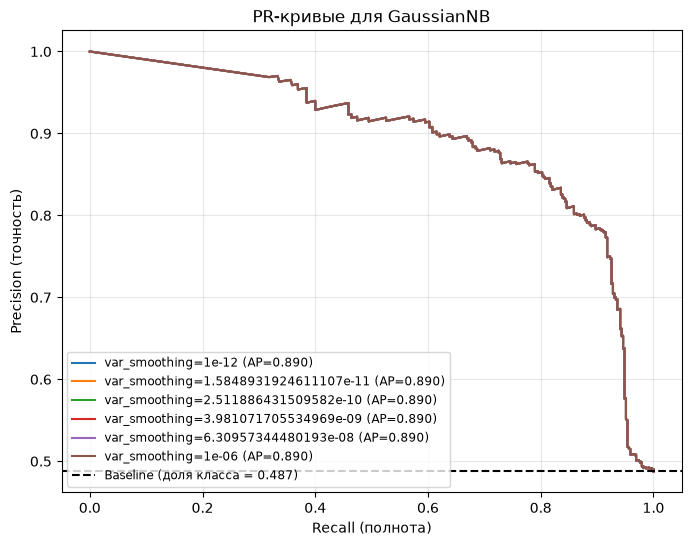


 РЕЗУЛЬТАТЫ ДЛЯ МОДЕЛИ: GaussianNB


,var_smoothing,Accuracy,Precision,Recall,F1,ROC_AUC
0,1.000000e-12,0.79625,0.89547,0.658974,0.759232,0.889578
1,1.584893e-11,0.79625,0.89547,0.658974,0.759232,0.889578
2,2.511886e-10,0.79625,0.89547,0.658974,0.759232,0.889578
3,3.981072e-09,0.79625,0.89547,0.658974,0.759232,0.889578
4,6.309573e-08,0.79625,0.89547,0.658974,0.759232,0.889578
5,1.000000e-06,0.79625,0.89547,0.658974,0.759232,0.889578



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'var_smoothing': 1e-12}
Accuracy:  0.7963
Precision: 0.8955
Recall:    0.6590
F1-score:  0.7592
ROC_AUC:   0.8896


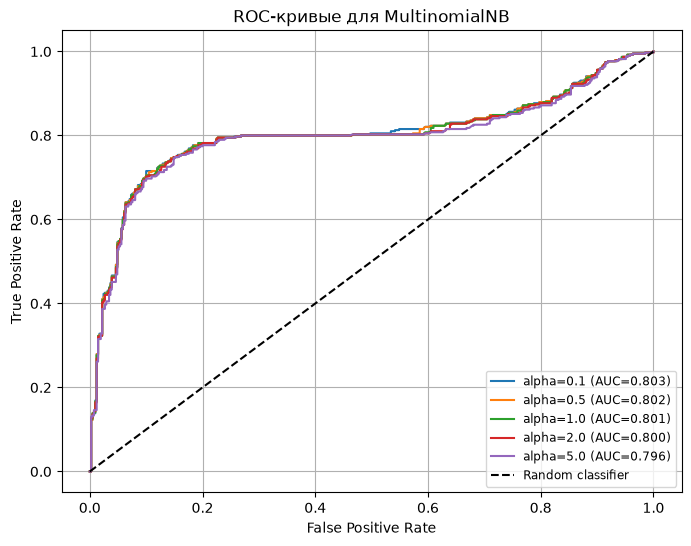

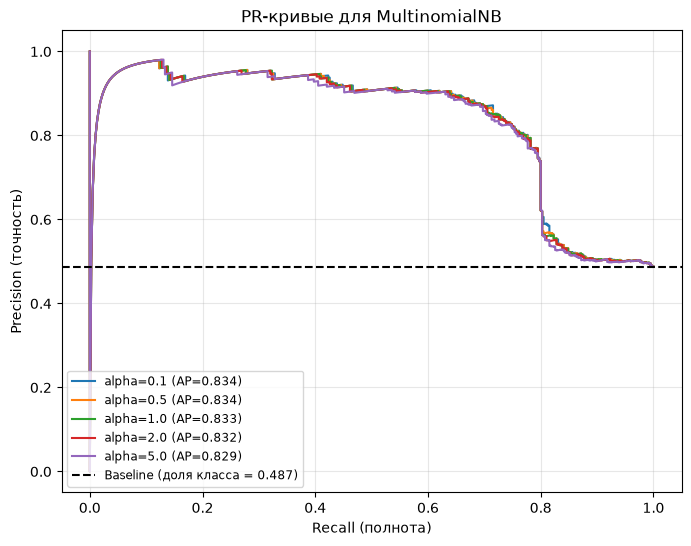


 РЕЗУЛЬТАТЫ ДЛЯ МОДЕЛИ: MultinomialNB


,alpha,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.1,0.79500,0.800532,0.771795,0.785901,0.803143
1,0.5,0.79500,0.800532,0.771795,0.785901,0.801992
2,1.0,0.79375,0.800000,0.769231,0.784314,0.801048
3,2.0,0.79250,0.799465,0.766667,0.782723,0.799534
4,5.0,0.78875,0.797844,0.758974,0.777924,0.796101



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'alpha': 0.1}
Accuracy:  0.7950
Precision: 0.8005
Recall:    0.7718
F1-score:  0.7859
ROC_AUC:   0.8031


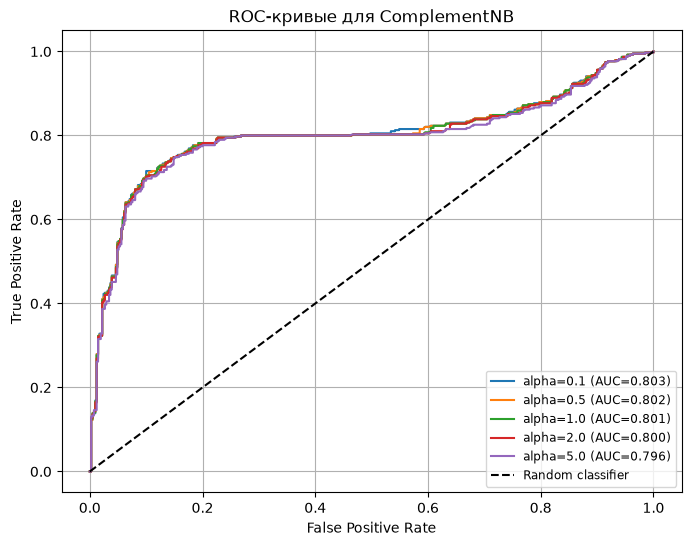

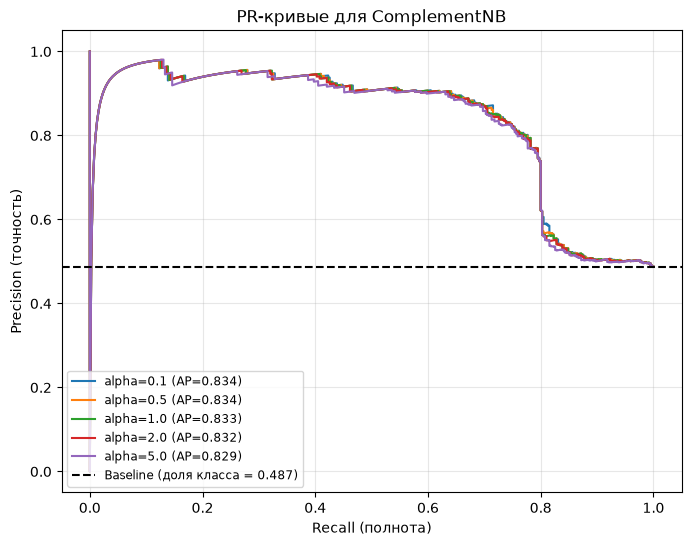


 РЕЗУЛЬТАТЫ ДЛЯ МОДЕЛИ: ComplementNB


,alpha,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.1,0.765,0.739336,0.8,0.768473,0.803143
1,0.5,0.765,0.739336,0.8,0.768473,0.801992
2,1.0,0.765,0.739336,0.8,0.768473,0.801048
3,2.0,0.765,0.739336,0.8,0.768473,0.799534
4,5.0,0.765,0.739336,0.8,0.768473,0.796101



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'alpha': 0.1}
Accuracy:  0.7650
Precision: 0.7393
Recall:    0.8000
F1-score:  0.7685
ROC_AUC:   0.8031


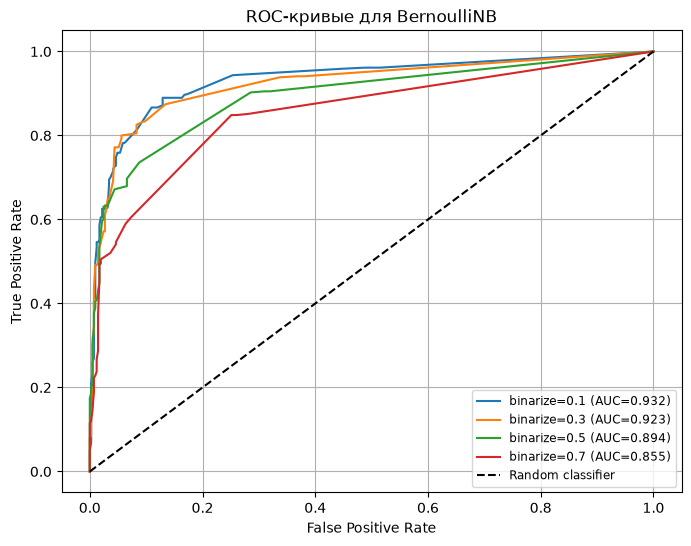

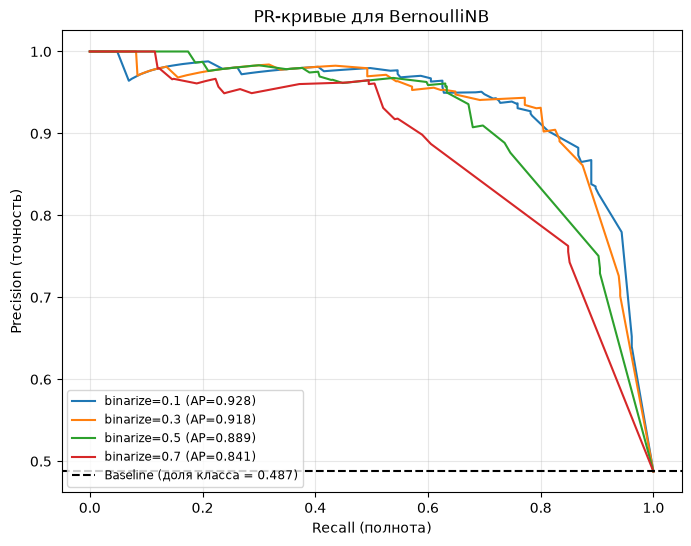


 РЕЗУЛЬТАТЫ ДЛЯ МОДЕЛИ: BernoulliNB


,binarize,Accuracy,Precision,Recall,F1,ROC_AUC
1,0.3,0.87375,0.931343,0.800000,0.860690,0.923352
0,0.1,0.86250,0.924242,0.782051,0.847222,0.931929
2,0.5,0.82500,0.876506,0.746154,0.806094,0.894059
3,0.7,0.79750,0.762673,0.848718,0.803398,0.854803



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'binarize': 0.3}
Accuracy:  0.8738
Precision: 0.9313
Recall:    0.8000
F1-score:  0.8607
ROC_AUC:   0.9234


In [184]:


def evaluate_model(model, params, X_train, X_test, y_train, y_test):
    model.set_params(**params)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        "Params": params,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "y_proba": y_proba
    }


param_grids = {
    "GaussianNB": {"var_smoothing": np.logspace(-12, -6, 6)},
    "MultinomialNB": {"alpha": [0.1, 0.5, 1.0, 2.0, 5.0]},
    "ComplementNB": {"alpha": [0.1, 0.5, 1.0, 2.0, 5.0]},
    "BernoulliNB": {"binarize": [0.1, 0.3, 0.5, 0.7]}
}


model_classes = {
    "GaussianNB": GaussianNB,
    "MultinomialNB": MultinomialNB,
    "ComplementNB": ComplementNB,
    "BernoulliNB": BernoulliNB
}

results_tables = {}

for model_name, grid in param_grids.items():
    grid_search = GridSearchCV(
        estimator=model_classes[model_name](),
        param_grid=grid,
        scoring='accuracy',
        cv=5,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    X_tr = X_train_scaled if model_name == "GaussianNB" else X_train
    X_te = X_test_scaled if model_name == "GaussianNB" else X_test
    grid_search.fit(X_tr, y_train)

    cv_results = pd.DataFrame(grid_search.cv_results_)
       
    model_results = []
    for _, row in cv_results.iterrows():
        params = row['params']

        model = model_classes[model_name](**params)
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_te)
        y_proba = model.predict_proba(X_te)[:, 1]

        model_results.append({
            'Params': params,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
            'Recall': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
            'F1': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
            'ROC_AUC': roc_auc_score(y_test, y_proba),
            'y_proba': y_proba
        })


    results_tables[model_name] = pd.DataFrame([
        {**r["Params"], **{k: v for k, v in r.items() if k not in ["Params", "y_proba"]}}
        for r in model_results
    ])

    plt.figure(figsize=(8, 6))
    for r in model_results:
        label = ", ".join([f"{k}={v}" for k, v in r["Params"].items()])
        fpr, tpr, _ = roc_curve(y_test, r["y_proba"], pos_label=1)
        auc_value = roc_auc_score(y_test, r["y_proba"])
        plt.plot(fpr, tpr, label=f"{label} (AUC={auc_value:.3f})")

    plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
    plt.title(f"ROC-кривые для {model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc='lower right', fontsize='small')
    plt.grid()
    plt.show()
    plt.figure(figsize=(8, 6))
    for r in model_results:
        label = ", ".join([f"{k}={v}" for k, v in r["Params"].items()])

        precision_curve, recall_curve, _ = precision_recall_curve(y_test, r["y_proba"], pos_label=1)
        ap = average_precision_score(y_test, r["y_proba"], pos_label=1)

        plt.plot(recall_curve, precision_curve, label=f"{label} (AP={ap:.3f})")

    baseline = sum(y_test == 1) / len(y_test)
    plt.axhline(baseline, color='k', ls='--', label=f'Baseline (доля класса = {baseline:.3f})')

    plt.title(f'PR-кривые для {model_name}')
    plt.xlabel('Recall (полнота)')
    plt.ylabel('Precision (точность)')
    plt.legend(loc='lower left', fontsize='small')
    plt.grid(alpha=0.3)
    plt.show()

    print(f"\n РЕЗУЛЬТАТЫ ДЛЯ МОДЕЛИ: {model_name}")
    display(results_tables[model_name].sort_values('Accuracy', ascending=False).head(10))
    best_row = results_tables[model_name].sort_values('Accuracy', ascending=False).iloc[0]
    best_params = {k: v for k, v in best_row.items() if k in grid_search.param_grid.keys()}

    best_model = model_classes[model_name](**best_params)
    best_model.fit(X_tr, y_train)

    y_pred_test = best_model.predict(X_te)
    y_proba_test = best_model.predict_proba(X_te)[:, 1]

    print("\nИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ")
    print(f"Лучшие параметры: {best_params}")
    print(f"Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
    print(f"ROC_AUC:   {roc_auc_score(y_test, y_proba_test):.4f}")

**Интерпретация результатов**


- **GaussianNB (параметр var_smoothing)**

    Параметр var_smoothing добавляет дисперсию к признакам для стабильности вычислений. Чем он больше, тем сильнее «сглаживание» (регуляризация).

    На этих данных параметр никак не влияет на модель, метрики одинаковы для всех значений.


- **MultinomialNB (параметр alpha)**

    alpha — параметр сглаживания

    Влияние крайне слабое: от alpha=0.1 до 5.0 метрики меняются в пределах 0.5–1%.

    Лучший результат при alpha=0.1: F1 = 0.786, ROC_AUC = 0.803.

    *Вывод:* модель устойчива к alpha на этих данных. Сильного переобучения при малых alpha не наблюдается.


- **ComplementNB (параметр alpha)**
    

    ComplementNB — вариант MNB, устойчивый к дисбалансу классов.

    Практически не зависит от alpha: все метрики (кроме ROC_AUC, падающего с 0.803 до 0.796) идентичны при любом alpha в диапазоне 0.1–5.0.

    *Вывод:* гиперпараметр не влияет на модель в этом диапазоне.


- **BernoulliNB (параметр binarize)**

    binarize — порог, выше которого значение признака считается 1 (признак присутствует).

    Влияние очень сильное, есть чёткий оптимум.

    Лучший результат при binarize = 0.3: Accuracy = 0.874, Precision = 0.931, F1 = 0.861, ROC_AUC = 0.932.

    При 0.1 — почти так же (F1 = 0.847, ROC_AUC = 0.932), но чуть ниже Recall (0.782 vs 0.800).

    При 0.5 и 0.7 — резкое падение ROC_AUC (0.894 -> 0.855) и Precision (0.877 -> 0.763). Модель начинает «терять» признаки, т.к. порог отсекает слишком много информации.

    *Вывод:* данные по своей природе бинарные, поэтому BernoulliNB с порогом 0.1 или 0.3  идеально соответствует структуре признаков.

### Дерево решений

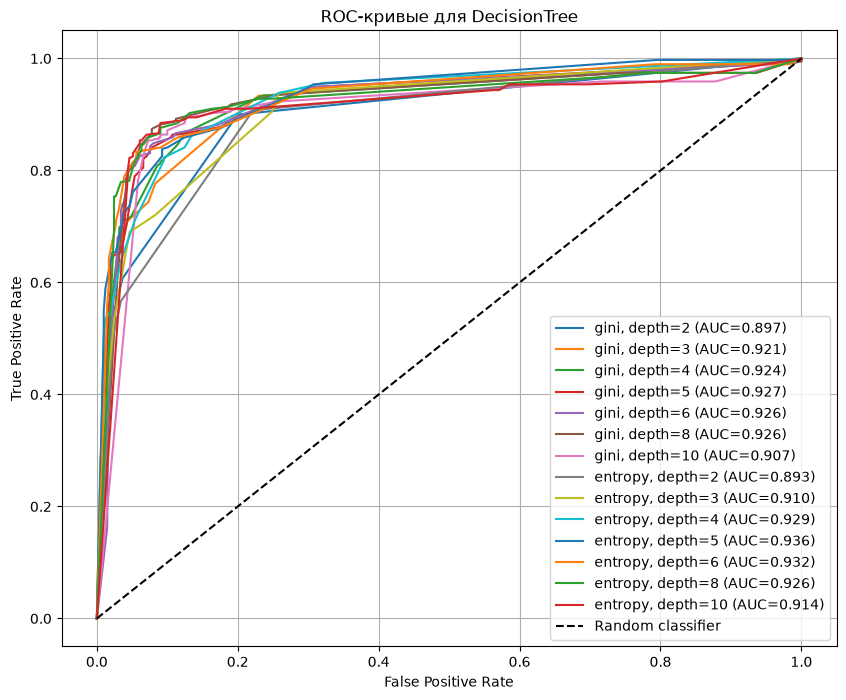

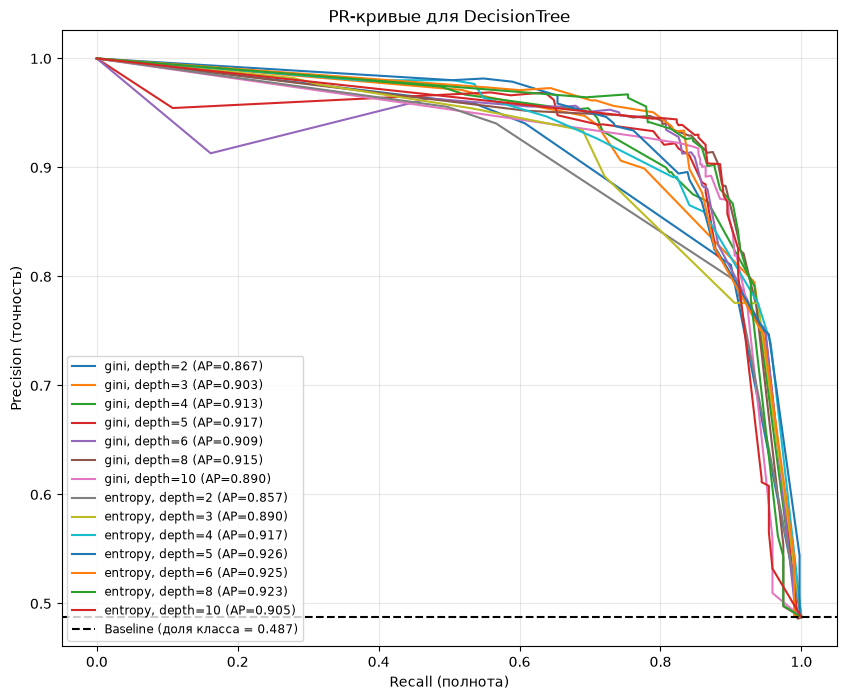

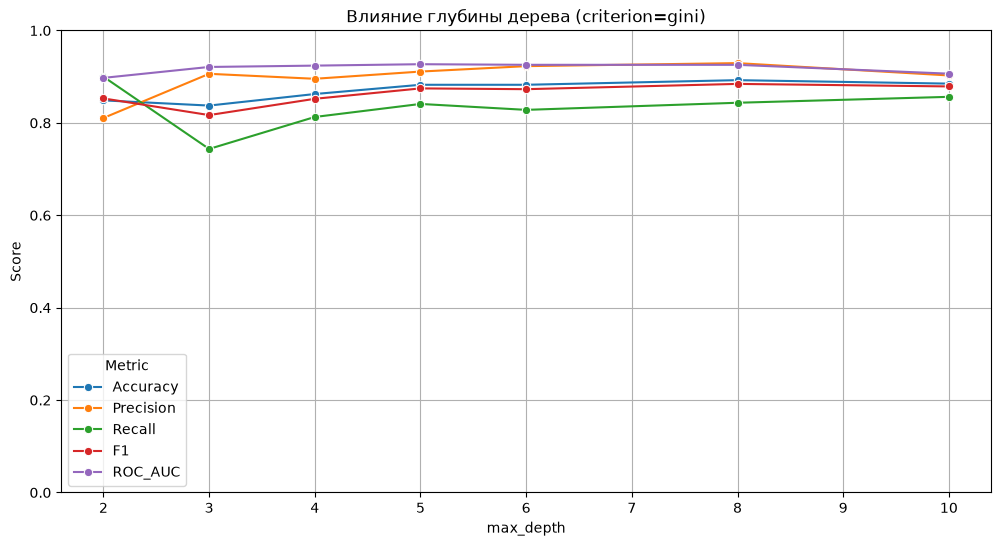

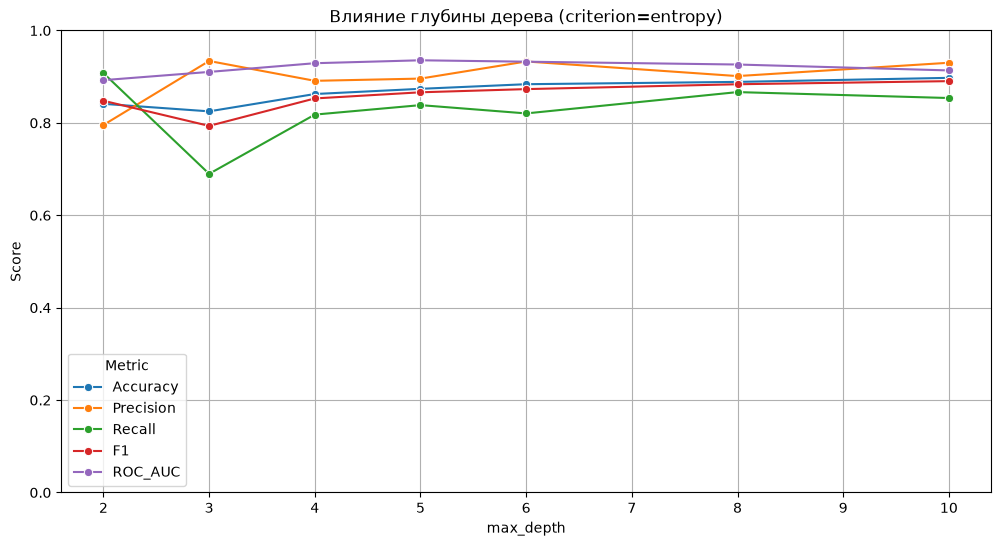

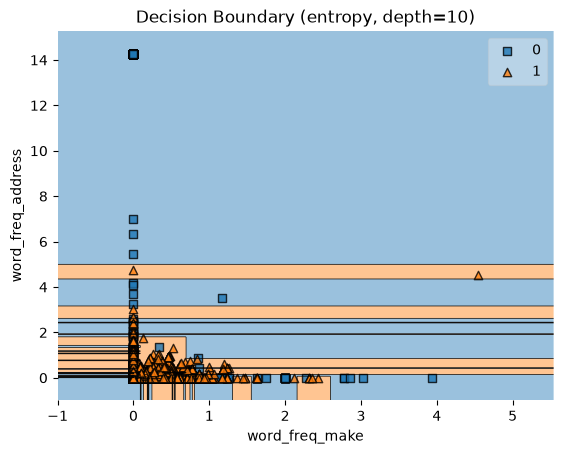

Таблица метрик для DecisionTree:


,criterion,max_depth,Accuracy,Precision,Recall,F1,ROC_AUC
13,entropy,10,0.89750,0.930168,0.853846,0.890374,0.913571
5,gini,8,0.89250,0.929379,0.843590,0.884409,0.925675
12,entropy,8,0.88875,0.901333,0.866667,0.883660,0.926360
6,gini,10,0.88500,0.902703,0.856410,0.878947,0.906548
11,entropy,6,0.88375,0.932945,0.820513,0.873124,0.932477
3,gini,5,0.88250,0.911111,0.841026,0.874667,0.927036
4,gini,6,0.88250,0.922857,0.828205,0.872973,0.925738
10,entropy,5,0.87375,0.895890,0.838462,0.866225,0.935510
2,gini,4,0.86250,0.895480,0.812821,0.852151,0.923968
9,entropy,4,0.86250,0.891061,0.817949,0.852941,0.929181



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'criterion': 'entropy', 'max_depth': 10}
Accuracy:  0.8975
Precision: 0.9302
Recall:    0.8538
F1-score:  0.8904
ROC_AUC:   0.9136


In [185]:
param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10]
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    refit=False
)
grid_dt.fit(X_train, y_train)

results = []
for params in grid_dt.cv_results_['params']:
    model = DecisionTreeClassifier(**params, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "Params": params,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "y_proba": y_proba
    })

results_df = pd.DataFrame([
    {**r["Params"], **{k: v for k, v in r.items() if k not in ["Params", "y_proba"]}}
    for r in results
])

plt.figure(figsize=(10, 8))
for r in results:
    label = f"{r['Params']['criterion']}, depth={r['Params']['max_depth']}"
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"], pos_label=1)
    auc_value = roc_auc_score(y_test, r["y_proba"])
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.title('ROC-кривые для DecisionTree')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid()
plt.show()

plt.figure(figsize=(10, 8))
for r in results:
    label = f"{r['Params']['criterion']}, depth={r['Params']['max_depth']}"
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, r["y_proba"], pos_label=1)
    ap = average_precision_score(y_test, r["y_proba"], pos_label=1)
    plt.plot(recall_curve, precision_curve, label=f"{label} (AP={ap:.3f})")

baseline = sum(y_test == 1) / len(y_test)
plt.axhline(baseline, color='k', ls='--', label=f'Baseline (доля класса = {baseline:.3f})')
plt.title('PR-кривые для DecisionTree')
plt.xlabel('Recall (полнота)')
plt.ylabel('Precision (точность)')
plt.legend(loc='lower left', fontsize='small')
plt.grid(alpha=0.3)
plt.show()

melted = results_df.melt(
    id_vars=["criterion", "max_depth"],
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    var_name="Metric", value_name="Score"
)

for crit in ["gini", "entropy"]:
    subset = melted[melted["criterion"] == crit]
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=subset, x="max_depth", y="Score", hue="Metric", marker="o")
    plt.title(f"Влияние глубины дерева (criterion={crit})")
    plt.ylim(0, 1)
    plt.grid(True)
    plt.show()

best_params = results_df.sort_values(by="Accuracy", ascending=False).iloc[0][["criterion", "max_depth"]].to_dict()
best_model = DecisionTreeClassifier(**best_params, random_state=42)
best_model.fit(X_train, y_train)

def decision_boundary_plot(X, y, X_train, y_train, clf, feature_indexes, title=None):
    if hasattr(X, 'iloc'):
        feature1_name, feature2_name = X.columns[feature_indexes]
        X_feature_columns = X.iloc[:, feature_indexes].values
    else:
        feature1_name, feature2_name = f"Feature {feature_indexes[0]}", f"Feature {feature_indexes[1]}"
        X_feature_columns = X[:, feature_indexes]
        
    if hasattr(X_train, 'iloc'):
        X_train_feature_columns = X_train.iloc[:, feature_indexes].values
    else:
        X_train_feature_columns = X_train[:, feature_indexes]

    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    y_train_encoded = le.transform(y_train)

    clf_copy = copy.deepcopy(clf)
    clf_copy.fit(X_train_feature_columns, y_train_encoded)

    plot_decision_regions(X=X_feature_columns, y=y_encoded, clf=clf_copy)
    plt.xlabel(feature1_name)
    plt.ylabel(feature2_name)
    plt.title(title)
    plt.show()

feature_indexes = [0, 1]

decision_boundary_plot(X, y, X_train, y_train, best_model, feature_indexes,
                       title=f"Decision Boundary ({best_params['criterion']}, depth={best_params['max_depth']})")
print("Таблица метрик для DecisionTree:")
display(results_df.sort_values('Accuracy', ascending=False).head(10))



y_pred_test = best_model.predict(X_test)
y_proba_test = best_model.predict_proba(X_test)[:, 1]

print("\nИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ")
print(f"Лучшие параметры: {best_params}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"ROC_AUC:   {roc_auc_score(y_test, y_proba_test):.4f}")


**Интерпретация результатов**

- Влияние **max_depth (глубины дерева)**

    Лучшее значение: max_depth=10 при criterion='entropy' — Accuracy = 0.8975, F1 = 0.8904, Precision = 0.9302. Также высокую точку дает max_depth=8 при criterion='gini' (Accuracy = 0.8925, F1 = 0.8844).

    Худшее значение: max_depth=4 при criterion='entropy' — Accuracy = 0.8625, F1 = 0.8529, и max_depth=4 при gini (ROC_AUC = 0.9240). На малых глубинах дерево недообучается (слишком простые правила).

    *Вывод:* на этих данных глубокие деревья (8–10) показывают лучшие результаты по Accuracy и F1. При переходе от 5 к 8 и 10 метрики растут. Однако при gini, depth=10 метрика ROC_AUC падает до 0.9065 (по сравнению с 0.9257 при depth=8), что сигнализирует о начале переобучения.

- Влияние **критерия разбиения (criterion)**

    Лучшее значение: entropy — показывает максимальный Accuracy (0.8975), F1 (0.8904) и высочайший ROC_AUC (0.9355) на глубине 5.

    Худшее значение: gini — на глубоких деревьях (depth=10) уступает entropy по Accuracy (0.8850 против 0.8975) и сильно проседает по ROC_AUC (0.9065 против 0.9136). Однако на малых глубинах gini зачастую чуть стабильнее по ROC_AUC.

    *Вывод:* entropy — лучший выбор для этих данных: он дает наивысшую точность на глубине 10 и обеспечивает лучший ROC_AUC на средних глубинах. gini показывает чуть более слабые результаты при сильном увеличении глубины.

### Линейный дискриминантный анализ

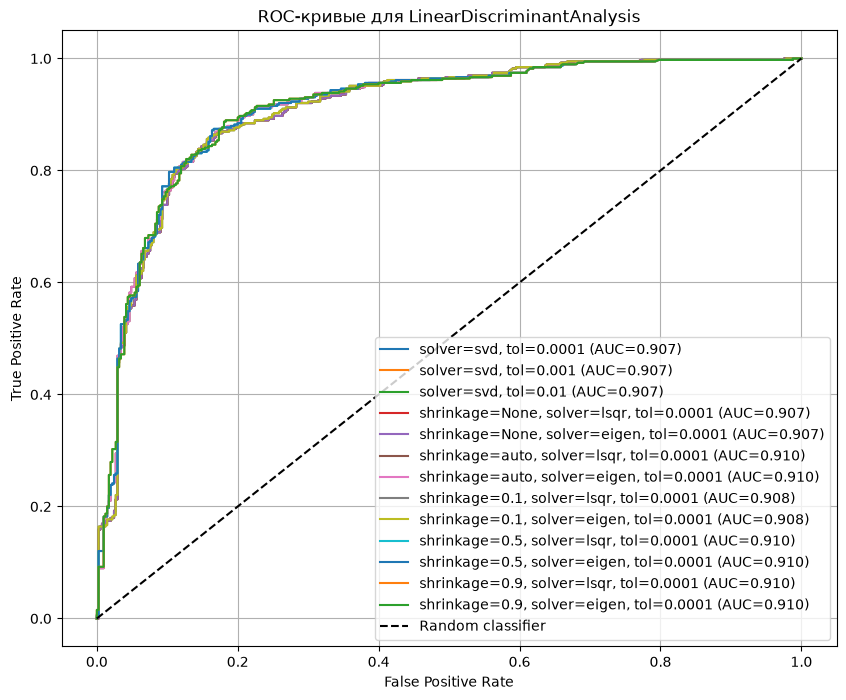

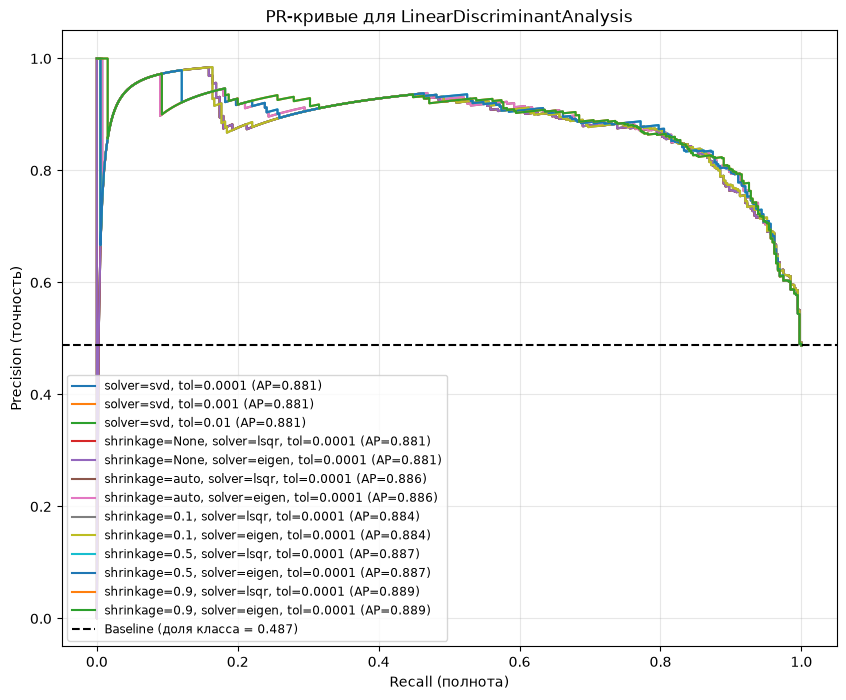

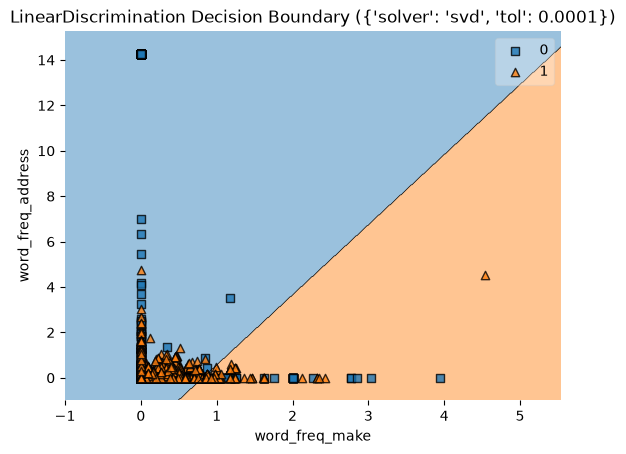

Таблица метрик для LinearDiscrimination:


,solver,tol,Accuracy,Precision,Recall,F1,ROC_AUC,shrinkage
0,svd,0.0001,0.81125,0.881789,0.707692,0.785206,0.906801,NaN
1,svd,0.0010,0.81125,0.881789,0.707692,0.785206,0.906801,NaN
2,svd,0.0100,0.81125,0.881789,0.707692,0.785206,0.906801,NaN
3,lsqr,0.0001,0.81125,0.881789,0.707692,0.785206,0.906801,None
4,eigen,0.0001,0.81125,0.881789,0.707692,0.785206,0.906801,None
8,eigen,0.0001,0.81000,0.878981,0.707692,0.784091,0.907758,0.1
7,lsqr,0.0001,0.81000,0.878981,0.707692,0.784091,0.907758,0.1
6,eigen,0.0001,0.80500,0.890000,0.684615,0.773913,0.909653,auto
5,lsqr,0.0001,0.80500,0.890000,0.684615,0.773913,0.909653,auto
9,lsqr,0.0001,0.80500,0.884868,0.689744,0.775216,0.910066,0.5



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'solver': 'svd', 'tol': 0.0001}
Accuracy:  0.8113
Precision: 0.8818
Recall:    0.7077
F1-score:  0.7852
ROC_AUC:   0.9068


In [186]:
param_grid_lda = [
    {"solver": ["svd"], "tol": [1e-4, 1e-3, 1e-2]},
    {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.1, 0.5, 0.9], "tol": [1e-4]}
]

grid_lda = GridSearchCV(
    LinearDiscriminantAnalysis(),
    param_grid_lda,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    refit=False
)
grid_lda.fit(X_train_scaled, y_train)

results = []
for params in grid_lda.cv_results_['params']:
    model = LinearDiscriminantAnalysis(**params)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        "Params": params,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "y_proba": y_proba
    })

results_df = pd.DataFrame([
    {**r["Params"], **{k: v for k, v in r.items() if k not in ["Params", "y_proba"]}}
    for r in results
])

plt.figure(figsize=(10, 8))
for r in results:
    label = ", ".join([f"{k}={v}" for k, v in r["Params"].items()])
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"], pos_label=1)
    auc_value = roc_auc_score(y_test, r["y_proba"])
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.title('ROC-кривые для LinearDiscriminantAnalysis')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid()
plt.show()

plt.figure(figsize=(10, 8))
for r in results:
    label = ", ".join([f"{k}={v}" for k, v in r["Params"].items()])
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, r["y_proba"], pos_label=1)
    ap = average_precision_score(y_test, r["y_proba"], pos_label=1)
    plt.plot(recall_curve, precision_curve, label=f"{label} (AP={ap:.3f})")

baseline = sum(y_test == 1) / len(y_test)
plt.axhline(baseline, color='k', ls='--', label=f'Baseline (доля класса = {baseline:.3f})')
plt.title('PR-кривые для LinearDiscriminantAnalysis')
plt.xlabel('Recall (полнота)')
plt.ylabel('Precision (точность)')
plt.legend(loc='lower left', fontsize='small')
plt.grid(alpha=0.3)
plt.show()

best_index = max(range(len(results)), key=lambda i: results[i]["Accuracy"])
best_params = results[best_index]["Params"]
best_model = LinearDiscriminantAnalysis(**best_params)
best_model.fit(X_train_scaled, y_train)

feature_indexes = [0, 1]
decision_boundary_plot(X, y, X_train_scaled, y_train, best_model, feature_indexes,
                       title=f"LinearDiscrimination Decision Boundary ({best_params})")
print("Таблица метрик для LinearDiscrimination:")
display(results_df.sort_values('Accuracy', ascending=False).head(10))


y_pred_test = best_model.predict(X_test_scaled)
y_proba_test = best_model.predict_proba(X_test_scaled)[:, 1]

print("\nИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ")
print(f"Лучшие параметры: {best_params}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"ROC_AUC:   {roc_auc_score(y_test, y_proba_test):.4f}")

**Интерпретация результатов**

- **solver** - алгоритм решения

    solver определяет, каким методом вычисляется матрица рассеяния и её обращение: svd (по умолчанию, без явного обращения), lsqr (наименьшие квадраты, требует shrinkage), eigen (через собственные значения, также требует shrinkage).

    Без shrinkage (None/NaN) svd, lsqr и eigen дают идентичный результат: Accuracy = 0.811, Precision = 0.882, Recall = 0.708, F1 = 0.785, ROC_AUC = 0.907.

    С shrinkage='auto' результаты lsqr и eigen тоже совпадают между собой: F1 ≈ 0.774, ROC_AUC ≈ 0.910, но чуть ниже Accuracy (0.805) и Recall (0.685).

    *Вывод:* при отсутствии shrinkage выбор solver не влияет на качество — данные не требуют специального алгоритма. svd предпочтителен, т.к. работает без shrinkage и устойчивее к переобучению.

- **tol** - порог сходимости

    tol задаёт допуск для остановки итераций (актуален для lsqr/eigen).

    В диапазоне 0.0001–0.01 результаты полностью идентичны.

    Вывод: tol не влияет на модель на этих данных — задача хорошо обусловлена, и итерационный процесс сходится одинаково быстро при любом разумном допуске. Параметр можно не настраивать.

- **shrinkage** - регуляризация ковариационной матрицы

    shrinkage делает матрицу более стабильной (борьба с мультиколлинеарностью).

    Лучший результат при None/NaN (без регуляризации) — F1 = 0.785, ROC_AUC = 0.907; и 'auto' (авто-подбор) — ROC_AUC = 0.910 (лучше ранжирование, но ниже Recall: 0.685 против 0.708).

    *Вывод:* данные не мультиколлинеарны, поэтому регуляризация только вредит. 'auto' допустим, если нужен максимальный ROC_AUC.

### Метод ближайших соседей

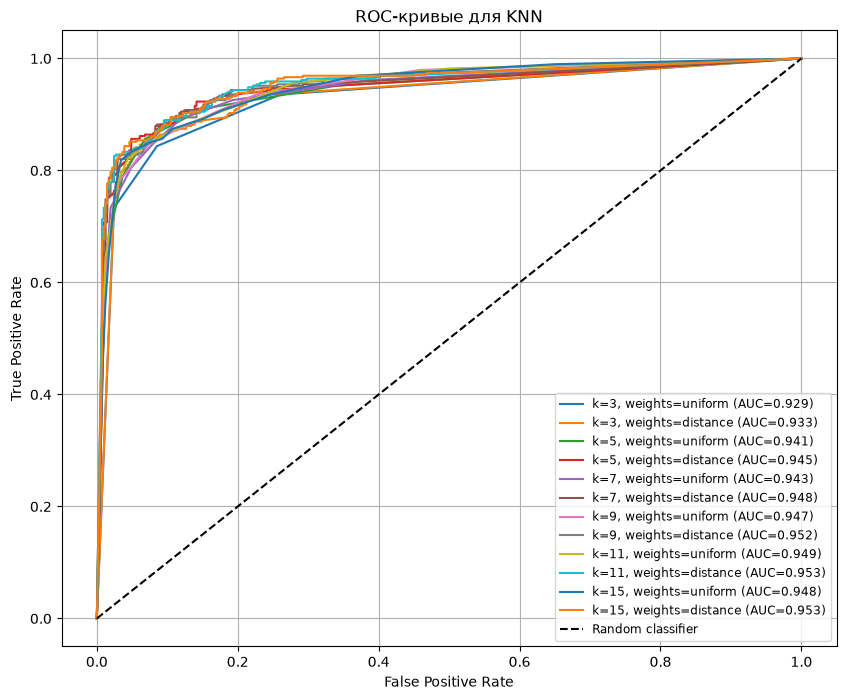

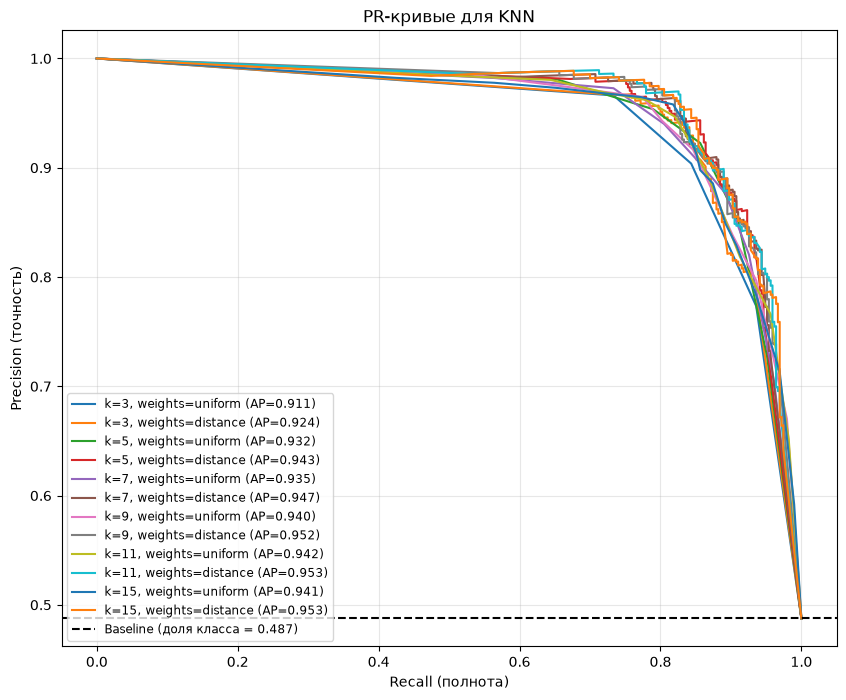

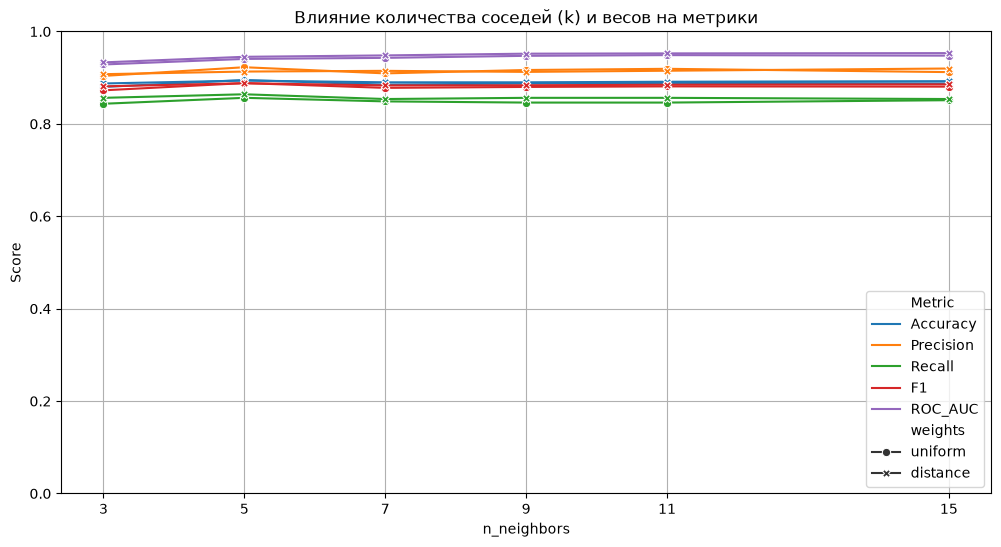

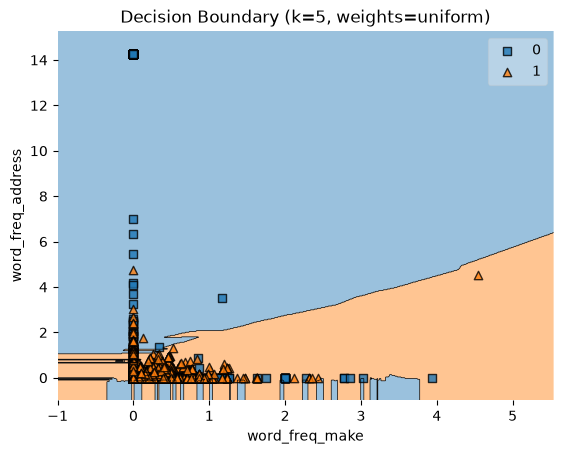


Таблица метрик для KNN:


,n_neighbors,weights,Accuracy,Precision,Recall,F1,ROC_AUC
2,5,uniform,0.89500,0.922652,0.856410,0.888298,0.940619
3,5,distance,0.89375,0.913279,0.864103,0.888011,0.945244
11,15,distance,0.89250,0.919890,0.853846,0.885638,0.953202
9,11,distance,0.89125,0.915068,0.856410,0.884768,0.952614
5,7,distance,0.89000,0.914835,0.853846,0.883289,0.948252
7,9,distance,0.89000,0.912568,0.856410,0.883598,0.952011
8,11,uniform,0.88875,0.919220,0.846154,0.881175,0.948859
1,3,distance,0.88750,0.907609,0.856410,0.881266,0.933155
10,15,uniform,0.88750,0.912088,0.851282,0.880637,0.947727
6,9,uniform,0.88750,0.916667,0.846154,0.880000,0.947326



ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: {'n_neighbors': 5, 'weights': 'uniform'}
Accuracy:  0.8950
Precision: 0.9227
Recall:    0.8564
F1-score:  0.8883
ROC_AUC:   0.9406


In [187]:
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    refit=False
)
grid_knn.fit(X_train_scaled, y_train)

results = []
for params in grid_knn.cv_results_['params']:
    model = KNeighborsClassifier(**params)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        "Params": params,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "y_proba": y_proba
    })

results_df = pd.DataFrame([
    {**r["Params"], **{k: v for k, v in r.items() if k not in ["Params", "y_proba"]}}
    for r in results
])

plt.figure(figsize=(10, 8))
for r in results:
    label = f"k={r['Params']['n_neighbors']}, weights={r['Params']['weights']}"
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"], pos_label=1)
    auc_value = roc_auc_score(y_test, r["y_proba"])
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.title('ROC-кривые для KNN')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize='small')
plt.grid()
plt.show()

plt.figure(figsize=(10, 8))
for r in results:
    label = f"k={r['Params']['n_neighbors']}, weights={r['Params']['weights']}"
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, r["y_proba"], pos_label=1)
    ap = average_precision_score(y_test, r["y_proba"], pos_label=1)
    plt.plot(recall_curve, precision_curve, label=f"{label} (AP={ap:.3f})")

baseline = sum(y_test == 1) / len(y_test)
plt.axhline(baseline, color='k', ls='--', label=f'Baseline (доля класса = {baseline:.3f})')
plt.title('PR-кривые для KNN')
plt.xlabel('Recall (полнота)')
plt.ylabel('Precision (точность)')
plt.legend(loc='lower left', fontsize='small')
plt.grid(alpha=0.3)
plt.show()

melted = results_df.melt(
    id_vars=["n_neighbors", "weights"],
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.lineplot(data=melted, x="n_neighbors", y="Score", hue="Metric",
             style="weights", markers=True, dashes=False)
plt.title("Влияние количества соседей (k) и весов на метрики")
plt.xticks(sorted(results_df["n_neighbors"].unique()))
plt.ylim(0, 1)
plt.grid(True)
plt.legend(loc='lower right')
plt.show()

best_idx = results_df["Accuracy"].idxmax()
best_params = results_df.iloc[best_idx][["n_neighbors", "weights"]].to_dict()
best_params['n_neighbors'] = int(best_params['n_neighbors'])

best_model = KNeighborsClassifier(**best_params)
best_model.fit(X_train_scaled, y_train)

feature_indexes = [0, 1]
decision_boundary_plot(
    X, y, X_train_scaled, y_train, best_model, feature_indexes,
    title=f"Decision Boundary (k={best_params['n_neighbors']}, weights={best_params['weights']})"
)
print("\nТаблица метрик для KNN:")
display(results_df.sort_values('Accuracy', ascending=False).head(10))

y_pred_test = best_model.predict(X_test_scaled)
y_proba_test = best_model.predict_proba(X_test_scaled)[:, 1]

print("\nИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ")
print(f"Лучшие параметры: {best_params}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"ROC_AUC:   {roc_auc_score(y_test, y_proba_test):.4f}")

**Интерпретация результатов**

- **n_neighbors** — число соседей

    Лучшие значения: n_neighbors=15 при weights='distance' — Accuracy = 0.8925, F1 = 0.8856, ROC_AUC = 0.9532 и  n_neighbors=5 при weights='uniform' (Accuracy = 0.8950, F1 = 0.8883).

    Худшее значение: n_neighbors=9 при weights='uniform' — Accuracy = 0.8875, F1 = 0.8800, ROC_AUC = 0.9473. Явного недообучения при больших k не наблюдается.

    *Вывод:* на этих данных KNN показывает себя очень стабильно. Увеличение числа соседей не приводит к сильному падению качества. Оптимальный диапазон k — от 5 до 15.

- **weights** — веса соседей

    'distance' — дает чуть более высокий ROC_AUC (например, 0.9532 при k=15 против 0.9477 при k=15 с 'uniform'). Но  разница между 'distance' и 'uniform' очень мала (в пределах 0.2–0.5%). 

    *Вывод:* weights='distance' показывает чуть лучшие результаты по метрике ROC_AUC, однако на этих данных разница между двумя типами весов не критична.

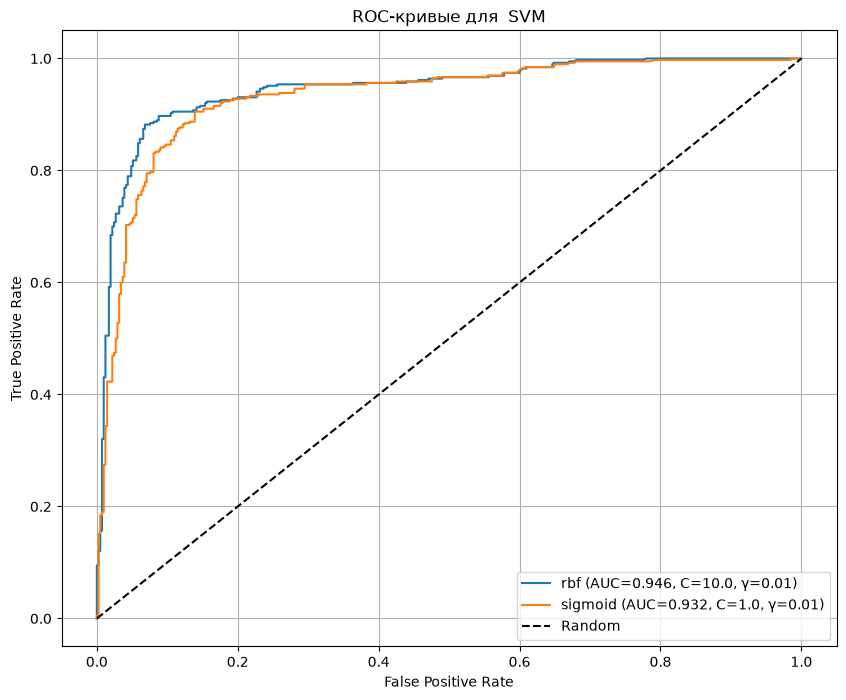

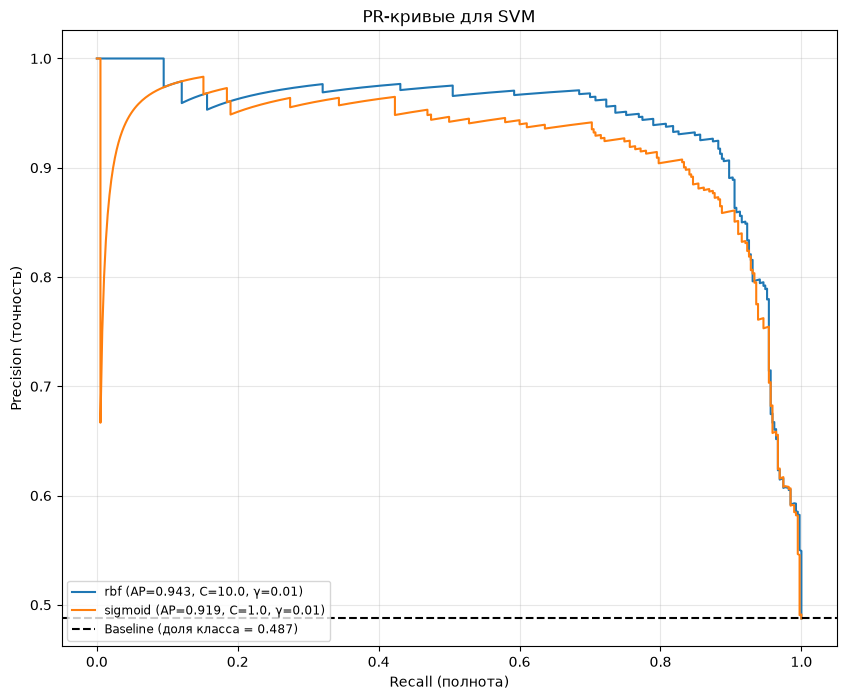


Лучшие параметры: kernel=rbf, C=10.0, gamma=scale, ROC_AUC=0.9310


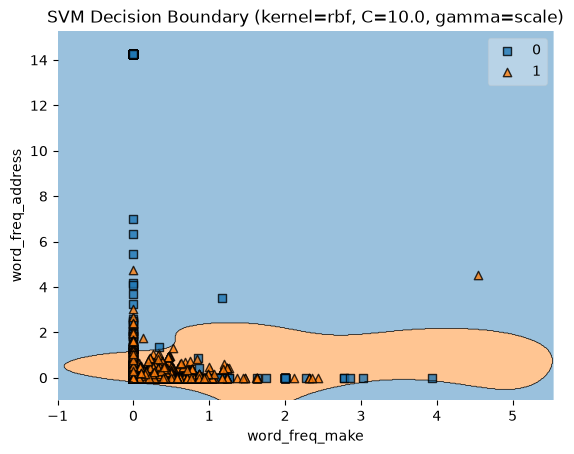

Таблица метрик для SVM:


,kernel,C,gamma,Accuracy,Precision,Recall,F1-score,ROC_AUC
7,rbf,10.0,scale,0.90500,0.938547,0.861538,0.898396,0.930985
3,rbf,1.0,scale,0.89375,0.924791,0.851282,0.886515,0.935538
9,rbf,10.0,0.01,0.89250,0.931818,0.841026,0.884097,0.946132
5,rbf,1.0,0.01,0.89125,0.931624,0.838462,0.882591,0.943655
10,sigmoid,10.0,0.01,0.86750,0.908046,0.810256,0.856369,0.913999
6,sigmoid,1.0,0.01,0.86250,0.909357,0.797436,0.849727,0.932123
1,linear,1.0,scale,0.85500,0.902941,0.787179,0.841096,0.934487
2,linear,10.0,scale,0.85500,0.902941,0.787179,0.841096,0.934487
0,linear,0.1,scale,0.85375,0.902655,0.784615,0.839506,0.934293
4,sigmoid,1.0,scale,0.79250,0.797872,0.769231,0.783290,0.823505


Лучшие параметры: kernel            rbf
C                10.0
gamma           scale
Accuracy        0.905
Precision    0.938547
Recall       0.861538
F1-score     0.898396
ROC_AUC      0.930985
Name: 7, dtype: object

ИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ
Лучшие параметры: kernel            rbf
C                10.0
gamma           scale
Accuracy        0.905
Precision    0.938547
Recall       0.861538
F1-score     0.898396
ROC_AUC      0.930985
Name: 7, dtype: object
Accuracy:  0.8950
Precision: 0.9227
Recall:    0.8564
F1-score:  0.8883
ROC_AUC:   0.9406


In [188]:


param_grid_linear = [{'C': [0.1, 1, 10]}]

param_grid_nonlinear = [{
    'kernel': ['rbf', 'sigmoid'],
    'C': [1, 10],
    'gamma': ['scale', 0.01]
}]
results = []

grid_linear = GridSearchCV(
    LinearSVC(random_state=42, max_iter=5000),
    param_grid_linear,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    refit=False
)

grid_linear.fit(X_train_scaled, y_train) 
cv_res_linear = pd.DataFrame(grid_linear.cv_results_)
for _, row in cv_res_linear.iterrows():
    p = row['params']
    clf = LinearSVC(C=p['C'], max_iter=5000, random_state=42)
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    y_score = clf.decision_function(X_test_scaled)
    
    results.append({
        'kernel':    'linear',
        'C':         p['C'],
        'gamma':     'scale', 
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        'F1-score':  f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        'ROC_AUC':   roc_auc_score(y_test, y_score),
    })

grid_nonlinear = GridSearchCV(
    SVC(random_state=42, max_iter=10000),
    param_grid_nonlinear,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    refit=False,
    verbose=0,
    return_train_score=False,
)
grid_nonlinear.fit(X_train_scaled, y_train)

cv_res = pd.DataFrame(grid_nonlinear.cv_results_)
for _, row in cv_res.iterrows():
    p = row['params']
    clf = SVC(kernel=p['kernel'], C=p['C'], gamma=p['gamma'], random_state=42)
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    y_score = clf.decision_function(X_test_scaled)
    results.append({
        'kernel':    p['kernel'],
        'C':         p['C'],
        'gamma':     p['gamma'],
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        'Recall':    recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        'F1-score':  f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        'ROC_AUC':   roc_auc_score(y_test, y_score),
    })


results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 8))
for kernel in ['rbf', 'sigmoid']:
    subset = results_df[results_df['kernel'] == kernel]
    if subset.empty:
        continue
    best_row = subset.loc[subset['ROC_AUC'].idxmax()]
    clf_best = SVC(kernel=kernel, C=best_row['C'],
                   gamma=best_row['gamma'], random_state=42)
    clf_best.fit(X_train_scaled, y_train)
    y_score = clf_best.decision_function(X_test_scaled)

    fpr, tpr, _ = roc_curve(y_test, y_score, pos_label=1)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr,
             label=f"{kernel} (AUC={roc_auc:.3f}, C={best_row['C']}, γ={best_row['gamma']})")

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.title("ROC-кривые для  SVM")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 8))
for kernel in ['rbf', 'sigmoid']:
    subset = results_df[results_df['kernel'] == kernel]
    if subset.empty:
        continue
    best_row = subset.loc[subset['ROC_AUC'].idxmax()]

    if kernel == 'linear':
        clf_best = LinearSVC(C=best_row['C'], max_iter=5000, random_state=42)
    else:
        clf_best = SVC(kernel=kernel, C=best_row['C'],
                       gamma=best_row['gamma'], random_state=42)
    clf_best.fit(X_train_scaled, y_train)
    y_score = clf_best.decision_function(X_test_scaled)

    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_score, pos_label=1)
    ap = average_precision_score(y_test, y_score, pos_label=1)
    plt.plot(recall_curve, precision_curve,
             label=f"{kernel} (AP={ap:.3f}, C={best_row['C']}, γ={best_row['gamma']})")

baseline = sum(y_test == 1) / len(y_test)
plt.axhline(baseline, color='k', ls='--',
            label=f'Baseline (доля класса = {baseline:.3f})')
plt.title('PR-кривые для SVM')
plt.xlabel('Recall (полнота)')
plt.ylabel('Precision (точность)')
plt.legend(loc='lower left', fontsize='small')
plt.grid(alpha=0.3)
plt.show()


best_idx = results_df['Accuracy'].idxmax()
best_params = results_df.loc[best_idx]
print(f"\nЛучшие параметры: kernel={best_params['kernel']}, "
      f"C={best_params['C']}, gamma={best_params['gamma']}, "
      f"ROC_AUC={best_params['ROC_AUC']:.4f}")

if best_params['kernel'] == 'linear':
    svm_clf = LinearSVC(C=best_params['C'], max_iter=5000, random_state=42)
else:
    svm_clf = SVC(kernel=best_params['kernel'], C=best_params['C'],
                  gamma=best_params['gamma'], random_state=42, max_iter=10000)
svm_clf.fit(X_train_scaled, y_train)



feature_indexes = [0, 1]
title1 = (f"SVM Decision Boundary (kernel={best_params['kernel']}, "
          f"C={best_params['C']}, gamma={best_params['gamma']})")
decision_boundary_plot(X, y, X_train_scaled, y_train, svm_clf, feature_indexes, title1)


print("Таблица метрик для SVM:")
display(results_df.sort_values('Accuracy', ascending=False).head(10))

print(f"Лучшие параметры: {best_params}")

y_pred_test = best_model.predict(X_test_scaled)
y_proba_test = best_model.predict_proba(X_test_scaled)[:, 1]

print("\nИТОГОВАЯ ПРОВЕРКА ЛУЧШЕЙ МОДЕЛИ НА ТЕСТЕ")
print(f"Лучшие параметры: {best_params}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_test, pos_label=1, zero_division=0):.4f}")
print(f"ROC_AUC:   {roc_auc_score(y_test, y_proba_test):.4f}")

**Интерпретация результатов**

- **kernel**— тип ядра

    Параметр определяет форму границы решений: linear — прямая/гиперплоскость, rbf — радиальные базисные функции (гибкая криволинейная граница), sigmoid — сигмоидная (близка к нейросетевой активации).

    Лучшее значение: rbf — наивысшая Accuracy = 0.9050, F1 = 0.8984, ROC_AUC = 0.9310 (при C=10.0, gamma='scale').

    Худшее значение: sigmoid — Accuracy = 0.7925, F1 = 0.7833, ROC_AUC = 0.8235 (при C=1.0, gamma='scale'). Модель показывает наихудшие результаты по всем метрикам, хотя и не скатывается к случайному угадыванию.

    *Вывод:* нелинейное ядро rbf показало себя лучше всех, что говорит о наличии нелинейных зависимостей в данных. linear дает стабильно высокий результат (~0.855), но уступает rbf. sigmoid оказался худшим выбором для этой задачи.

- **C** — параметр регуляризации

    Параметр задаёт штраф за ошибки: малый C — больше регуляризации, большой C — меньше регуляризации, риск переобучения.

    Лучшее значение: C = 10.0 — дает наивысшие результаты для rbf (Accuracy = 0.9050, ROC_AUC = 0.9310 при gamma='scale') и sigmoid (Accuracy = 0.8675, ROC_AUC = 0.9140 при gamma=0.01). Для linear значение C практически не влияет на результат (все три дают ROC_AUC ≈ 0.9345).

    Худшее значение: C = 1.0 для rbf (Accuracy = 0.8938, ROC_AUC = 0.9355 при gamma=0.01) и C = 0.1 для linear (Accuracy = 0.8538, ROC_AUC = 0.9343).

    *Вывод:* для нелинейных ядер (rbf и sigmoid) увеличение C до 10.0 заметно улучшает качество (снижается смещение), а для linear параметр C не играет существенной роли.

- **gamma** — коэффициент ядра (только для rbf и sigmoid)

   Параметр определяет «радиус влияния» одной точки: 'scale' = 1/(n_features × X.var()), меньшее значение (0.01) дает более гладкую границу.

    Лучшее значение: для rbf — gamma='scale' (Accuracy = 0.9050, ROC_AUC = 0.9310 при C=10.0). Для sigmoid лучший результат дает gamma=0.01 (Accuracy = 0.8675, ROC_AUC = 0.9140 при C=10.0).

    Худшее значение: gamma=0.01 для rbf (Accuracy = 0.8925, ROC_AUC = 0.9461 при C=10.0 — Примечание: ROC_AUC здесь даже выше, но Accuracy и F1 ниже) и gamma='scale' для sigmoid (Accuracy = 0.7925, ROC_AUC = 0.8235).

    *Вывод:* влияние gamma зависит от ядра. Для rbf значение 'scale' дает лучший баланс между Accuracy и F1, хотя gamma=0.01 обеспечивает чуть более высокий ROC_AUC. Для sigmoid, наоборот, жесткое значение 0.01 дает значительный прирост по сравнению с 'scale'.